# INTRODUCTION

The SEM Analysis: How Feed Experiences Shape Perceived Fairness of Social Media

**Data:** `Responses.xlsx`, a survey of social media users in the Netherlands, Germany, Spain and Greece (2025).

This analysis builds on two studies: Alashhy’s master’s thesis (2025) modelled perceived fairness as an outcome of four principles of justice, using survey data from the Netherlands. The follow-up paper (Dey et al., FAccT ‘26) extended the survey to four EU countries.

In this analysis, instead of justice principles, I test whether users’ psychological reactions to the algorithm, their sense of control and their suspicion of algorithmic curation, explain how feed experiences (content diversity, echo, visibility) shape perceived fairness. I build the constructs from the data, measure fairness with three questions, and test whether the effects differ across online language, gender, usage intensity and age, user groups not examined in the earlier studies.

# Main Research Question

#### How do users' experiences of their personalised feeds shape their perceived fairness of social media, through their sense of control and suspicion of algorithmic curation, and do these effects differ across user groups?

| Sub-Questions | Student | Student ID |
|---|---|---|
| SQ1. Antecedents → mediators: How do content diversity, echo and visibility shape users' sense of control and suspicion of algorithmic curation? | Huyen Nguyen | 500865505 |
| SQ2. Mediators → outcome: How do sense of control and suspicion of curation affect perceived fairness? | Yasmina Rietkerk | |
| SQ3. Mediation: To what extent do control and suspicion explain the link between feed experiences and perceived fairness?| Floris Mollenhof | |
| SQ4. Moderation: Do these relationships differ by online language, gender, usage intensity and age?| Daniil Malygin | |


- Antecedents  - what people experience in their feed: content diversity, echo, visibility 
- Mediator - how people interpret the algorithm: perceived control, suspicion of curation
- Moderator - user groups: online language, gender, usage, age
- Outcome : perceive of fairness 

#### Term definition:
- Diversity: How much a user's feed shows different opinions, topics and information.
- Echo: How much a user's feed shows content that agrees with their existing opinions and beliefs.
- Visibility: How much a user feels their own content is seen and heard by others.
- Perceived Control: How much a user feels they can influence what appears in their feed.
- Suspicion: How much a user believes the algorithm controls, filters or hides certain content.

#### What is SEM? 
SEM combines two things:
1. **Measurement model:** some ideas, like "fairness", can't be measured with one question. So we ask a few questions and let the model build a hidden factor from them.
2. **Structural model:** a set of regressions between these factors (arrows: A → B).

So SEM is like doing **factor analysis and regression at the same time**.
### Contents of Analysis:

- I. Import Python libraries and packages
- II. Data cleaning
- III. One-hot encoding
- IV. Descriptive statistics for endcoded data
- V. Group relevant survey questions into target variables
- VI. Check the SEM assumptions
- VII. Measurement model: do my question measure what I think?
- VIII. Structural model: answering sub-question 1
- IX. Cluster analysis for Sub-Question 1 ( to identify feed experience profiles)

**Sub-question 2, 3, 4 are analysed separately in notebooks prepared by other students** 


### The Model we are testing:

```
  ANTECEDENTS               MEDIATORS                             OUTCOME
  (feed experiences)    (how users interpret the algorithm)

  Content diversity ──┐
                      ├──►  Perceived control  ──┐
  Echo / confirmation ┤                          ├──►       Perceived fairness
                      ├──►  Suspicion of       ──┘
  Visibility / voice ─┘     algorithmic curation

  (+ direct arrows from each antecedent to fairness)
  Moderators: Online Language, Gender, Usage intensity, Age
```

| Factor | Role | Questions (codes) |
|---|---|---|
| **Diversity** | antecedent | UCD2 *different opinions on the same topic*, REVP5 *new ideas and topics*, ON1 *good mix to stay informed* |
| **Echo** | antecedent | REVP1 *top comments reflect what I think*, REVP2 *I scroll comments to find my view*, REVP3 *lots of agreement in comments* |
| **Visibility** | antecedent | BC2 *my content gets the same views as others*, BC3 *…as others from a different background*, ON3 *fair chance to be seen/heard* |
| **Control** | mediator | RAD1 *I feel in control of my feed*, RAD2 *I can influence my content* |
| **Suspicion** | mediator | DVP2 *one-sided political content*, DVP3 *algorithm shapes political topics*, ON2 *algorithm hides views*, DVP5 *shadowbans*, BC4 *some groups are prioritised* |
| **Fairness** | outcome | PF1 *I trust the algorithm to be fair*, PF2 *social media is fair (end)*, FAIR0 *social media is fair (start)* |

# I. Import Python libraries and packages

In [1]:

# If semopy (the SEM package) is not installed yet, this installs it first
try:
    import semopy
except ImportError:
    %pip install semopy
    import semopy

import pandas as pd                     # tables
import numpy as np                      # maths
import matplotlib.pyplot as plt         # charts
from scipy import stats                 # statistical tests
from sklearn.cluster import KMeans      # clustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("semopy version:", semopy.__version__)

/Users/huyennguyen/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/huyennguyen/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


semopy version: 2.3.11


In [2]:
#Load data
data = pd.read_excel("Responses.xlsx")

print("rows and columns: ", data.shape)
data.head(5)

rows and columns:  (685, 57)


,ID,Start time,Completion time,Email,Name,Last modified time,Please share your email address,In which country are you located?,What is your country of origin?,Which description fits your parents' country of origin the best?,...,I scroll through recommendations,I end up watching videos I didn't intend to watch,Scrolling feels like a habit rather than a conscious choice,I sometimes spend more time scrolling than I had planned,"I feel like my feed shows me a good mix of topics to stay informed (e.g., news, social issues, or different opinons)",I believe that the algorithm hides certain social or political views,I feel like I have a fair chance to be seen/heard,I trust the algorithm to recommend me content fairly,What matters most to you? (1 being the most important and the last number being the least important),I think social media is fair2
0,1,2025-11-04 16:03:57,2025-11-04 16:09:58,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Sometimes,Agree,Agree,Agree,Agree,Neutral,Neutral,Democratic values (respect for other views and...,Agree
1,2,2025-11-04 18:56:25,2025-11-04 19:00:13,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Rarely,Strongly agree,Strongly agree,Neutral,Strongly agree,Agree,Neutral,Equity (opportunities based upon your needs);A...,Neutral
2,3,2025-11-04 22:44:10,2025-11-04 22:51:50,anonymous,NaN,NaN,NaN,Netherlands,Spain,Both parents are born and brought up in the Spain,...,Sometimes,Sometimes,Strongly agree,Strongly agree,Strongly disagree,Strongly agree,Disagree,Strongly disagree,Equity (opportunities based upon your needs);A...,Strongly disagree
3,4,2025-11-05 07:47:43,2025-11-05 07:57:56,anonymous,NaN,NaN,NaN,Malta,Spain,Both parents are born and brought up in the Spain,...,Rarely,Sometimes,Disagree,Agree,Agree,Agree,Neutral,Neutral,Autonomy (ability to decide for myself);Democr...,Disagree
4,5,2025-11-05 09:03:17,2025-11-05 09:11:07,anonymous,NaN,NaN,NaN,The Netherlands,Spain,Both parents are born and brought up in the Spain,...,Often,Sometimes,Disagree,Agree,Disagree,Agree,Disagree,Strongly disagree,Equity (opportunities based upon your needs);D...,Strongly disagree


The raw data has 685 rows and 57 columns

# II. Data Cleaning

In [3]:
print("duplicated rows: ", data.duplicated().sum())


duplicated rows:  0


There is no duplicated value in the raw data

## Drop unnecessary columns

In [4]:
# Huyen:
# Drop NaN columns, axis=1: column
# Columns are dropped: Name,	Last modified time,	Please share your email address
data.dropna(axis=1, how="all", inplace=True)
data.shape


(685, 54)

In [5]:
# Huyen:
# Drop unnecessary columns
data.drop(columns=["Start time", "Completion time", "Email"], inplace=True)
data.shape

(685, 51)

## Rename columns:

column codes are used from the paper's appendix

In [6]:
# Huyen:
#Clean column headers
#replace " " with any whitespace character,having one or more occurences, interpret the first argument as a regular expression. 
# why: there are some columns contain non-breaking space which looks like normal space, but different character \xa0
data.columns = data.columns.str.replace(r"\s+", " ", regex=True).str.strip()

*learning source: how to remove spaces: https://accuweb.cloud/resource/articles/how-to-remove-spaces-from-a-string-in-python*

In [7]:
# Huyen
# Rename columns
data = data.rename(columns={
    "In which country are you located?": "country_located", 
    "What is your country of origin?": "country_origin",
    "Which description fits your parents' country of origin the best?": "parent_origin",
    "What's your highest/current level of education?": "education",
    "How many languages do you speak?": "n_languages",
    "Which languages do you use most online? (select all that applies)": "online_english",
    "What age group are you in?": "age", 
    "What is your gender?": "gender",
    "I use social media": "USE", 
    "I think social media is fair": "FAIR0",
    "I see repeated topics on my feed": "UCD1",
    "I see different opinions on the same topic": "UCD2",
    "My feed varies within my social circle": "UCD3",
    "I often notice that someone didn't know about a trend, which I thought everybody had seen": "UAE1",
    "It is harder for me to take part in a discussion regarding a topic when I have not seen the topic on my feed yet": "UAE2",
    "I notice that people mostly agree with what's trending, they rarely add their own personal views - add happens to options": "UAE3",
    "A topic/trend usually stays on my feed for ...": "UAE4",
    "When I see a post and open the comments, the top comments reflect what I am already thinking about": "REVP1",
    "I scroll through the comments to see if someone has mentioned what I am thinking about": "REVP2",
    "I notice a lot of agreement with the content in the comments": "REVP3",
    "I tend to comment on content I disagree with": "REVP4",
    "I often see new ideas and topics on my feed": "REVP5",
    "When I see a new topic on my feed, I tend to scroll away": "REVP6",
    "My feed does not show information that others could be seeing": "BC1",
    "I feel like my content gets the same number of views as content from others": "BC2",
    "I feel like my content gets the same number of views as content from others with a different background (e.g., race, gender, age) than mine": "BC3",
    "I think content from certain groups of people is prioritized over other groups": "BC4",
    "I am informed that my feed is shaped by personal information like my age, gender or location - transparency": "BC5",
    "I would feel comfortable swapping feeds with someone from a different background than mine (e.g., age, race, beliefs)": "NCR1",
    "If everyone got my feed, I think some people might be shocked by the content they see": "NCR2",
    "I would be okay seeing less of my favorite type of content if it meant more equal exposure for everyone": "NCR3",
    "If I had to exchange feeds with someone really different from me, I don't think I would like what I would see": "NCR4",
    "When I post about topics like politics or social issues, it feels like my voice can be seen and heard": "DVP1",
    "I have seen political content that felt one-sided or biased": "DVP2",
    "I feel like the algorithm shapes what political topics I get to see": "DVP3",
    "I rarely see posts that challenge my own political views unless I search for them": "DVP4",
    "I've seen creators mention that their political-related content was shadowbanned": "DVP5",
    "I feel I am in control of my feed": "RAD1",
    "I can influence the type of content I get on my feed": "RAD2",
    "The algorithm decides what I watch": "RAD3",
    "I scroll through recommendations": "RAD4",
    "I end up watching videos I didn't intend to watch": "RAD5",
    "Scrolling feels like a habit rather than a conscious choice": "RAD6",
    "I sometimes spend more time scrolling than I had planned": "RAD7",
    "I feel like my feed shows me a good mix of topics to stay informed (e.g., news, social issues, or different opinons)": "ON1",
    "I believe that the algorithm hides certain social or political views": "ON2",
    "I feel like I have a fair chance to be seen/heard": "ON3",
    "I trust the algorithm to recommend me content fairly": "PF1",
    "I think social media is fair2": "PF2"
})

In [8]:
print(data.columns)
print(data.shape)

Index(['ID', 'country_located', 'country_origin', 'parent_origin', 'education',
       'n_languages', 'online_english', 'age', 'gender', 'USE', 'FAIR0',
       'UCD1', 'UCD2', 'UCD3', 'UAE1', 'UAE2', 'UAE3', 'UAE4', 'REVP1',
       'REVP2', 'REVP3', 'REVP4', 'REVP5', 'REVP6', 'BC1', 'BC2', 'BC3', 'BC4',
       'BC5', 'NCR1', 'NCR2', 'NCR3', 'NCR4', 'DVP1', 'DVP2', 'DVP3', 'DVP4',
       'DVP5', 'RAD1', 'RAD2', 'RAD3', 'RAD4', 'RAD5', 'RAD6', 'RAD7', 'ON1',
       'ON2', 'ON3', 'PF1',
       'What matters most to you? (1 being the most important and the last number being the least important)',
       'PF2'],
      dtype='str')
(685, 51)


# Check value consistency

In [9]:
data["country_located"].value_counts()

country_located
Netherlands               123
Germany                   118
Spain                      85
Greece                     58
Netherlands                50
                         ... 
India                       1
Amsterxam                   1
Uithoorn                    1
Amsterdam                   1
Netherlands, Amsterdam      1
Name: count, Length: 71, dtype: int64

# Adding Consistency to the collumns
#Author Floris Mollenhof 
In this code I'm gonna add consistency to the following collumns; country, country_origin and parent_origin? I'm going to do this because in the collumns there are many ways of writing countries for example and whe want 1 version of it so that it is more consistent. I'm doing this through the function replace and expeting that there is one consistent name left in the collumns. 

In [10]:
#Author Floris Mollenhof
# Standardise country of residence
col = "country_located"
data[col] = data[col].str.strip().str.lower()   # remove spaces and capitals

data[col] = data[col].replace({
    # Netherlands
    "nederland": "netherlands",
    "the netherlands": "netherlands",
    "holland": "netherlands",
    "netherland": "netherlands",
    "netherlands, amsterdam": "netherlands",
    "the netherlans": "netherlands",
    "amsterdam": "netherlands",
    "amsterxam": "netherlands",
    "nl": "netherlands",
    "niederlande": "netherlands",
    "uithoorn": "netherlands",
    # Germany
    "deutschland": "germany",
    "german": "germany",
    # Spain
    "españa": "spain",
    # Greece
    "greece.": "greece",
    # Other countries
    "uk": "united kingdom",
    "england": "united kingdom",
    "usa": "united states",
    "cairo": "egypt",
    "turkiye": "turkey",
    "تركيا": "turkey",                          # Arabic for Turkey
    # Not a country -> missing
    "spiliotopoulos": np.nan,                   # surname, not a location
    "netherworld": np.nan                       # unclear answer
})

data[col] = data[col].str.title()   # back to "Netherlands"

data[col].value_counts()


country_located
Netherlands       297
Germany           151
Spain             113
Greece             76
Austria             4
United Kingdom      4
Malta               3
Canada              3
France              3
Sweden              3
United States       2
Egypt               2
Belgium             2
Turkey              2
Morocco             2
Portugal            2
New Zealand         1
Singapore           1
South Africa        1
Switzerland         1
Poland              1
Italy               1
Hong Kong           1
Jordan              1
Brazil              1
Norway              1
India               1
Name: count, dtype: int64

In [11]:
#Author Floris Mollenhof 
# Standardise country of origin
col = "country_origin"                          # adjust to your column name
data[col] = data[col].str.strip().str.lower()   # remove spaces and capitals

data[col] = data[col].replace({
    # Netherlands
    "nederland": "netherlands",
    "the netherlands": "netherlands",
    "holland": "netherlands",
    "netherland": "netherlands",
    "nehterlands": "netherlands",
    "nederlands": "netherlands",
    "nl": "netherlands",
    "dutch": "netherlands",
    "amsterdam": "netherlands",
    "fryslan": "netherlands",
    # Germany
    "german": "germany",
    "deutschland": "germany",
    "getmany": "germany",
    "germsny": "germany",
    # Spain
    "españa": "spain",
    # Greece
    "greek": "greece",
    "greece.": "greece",
    "creta island in greece": "greece",
    # Other spellings
    "syrien": "syria",
    "سورية": "syria",                            # Arabic for Syria
    "morrocco": "morocco",
    "morroco": "morocco",
    "marocco": "morocco",
    "surinam": "suriname",
    "kazahstan": "kazakhstan",
    "irland": "ireland",
    "frankrijk": "france",
    "turkiye": "turkey",
    "chinese": "china",
    "bulgarian": "bulgaria",
    "usa": "united states",
    "england": "united kingdom",
    # Multiple origins -> mixed
    "netherlands/greece": "mixed",
    "egypt/germany": "mixed",
    "ntherlands/surinam": "mixed",
    "netherlands/ spain": "mixed",
    "england/ spain": "mixed",
    "netherlands, ethnically from lebanon": "mixed",
    "dutch,surinamese & indonesian": "mixed",
    "suriname, molukken, irak": "mixed",
    "i was born in germany, but my family is originally from sri lanka.": "mixed",
    "born in syria but originally im palestinian.": "mixed",
    "my parents are from pakistan": "mixed",     # answer is about parents, not respondent
    # Not a country -> missing
    "yes": np.nan,
    "manerf": np.nan
})

data[col] = data[col].str.title()   # back to "Netherlands"
data[col].value_counts()

country_origin
Germany           177
Netherlands       145
Spain             132
Greece             92
Syria              24
Morocco            14
Mixed              11
India               6
Suriname            6
Portugal            4
Egypt               4
Colombia            3
China               3
Palestine           3
Nigeria             3
Lebanon             3
Taiwan              3
Ukraine             2
Vietnam             2
Indonesia           2
Canada              2
Italy               2
Turkey              2
United Kingdom      2
Pakistan            2
Romania             2
Brazil              2
Eritrea             2
France              2
Ghana               2
United States       1
Kazakhstan          1
Latvia              1
South Africa        1
Argentina           1
Ireland             1
Luxembourg          1
Bulgaria            1
Austria             1
Lithuania           1
Jamaica             1
Venezuela           1
Russia              1
Peru                1
Aruba            

In [12]:

data["parent_origin"].value_counts(dropna=False)

parent_origin
Both parents are from the EU                                      139
Both parents are from outside the EU                              138
Both parents are born and brought up in the Netherlands            93
Both parents are born and brought up in Germany                    60
Both parents are born and brought up in the Germany                60
One parent is from the EU and one parent is outside of the EU      51
Both parents are born and brought up in the Spain                  36
Both parents are born and brought up in Greece                     36
Both parents are born and brought up in Spain                      34
Both parents are born and brought up in the Greece                 15
Both parents are from EU                                            7
Both parents are from Greece                                        5
NaN                                                                 4
One parent is from Greece, and one parent is outside of Greece      4
One pa

In [13]:
#Author Floris Mollenhof
# Standardise parents' country of origin
col = "parent_origin"                                       # adjust to your column name
data[col] = data[col].str.replace("\xa0", " ").str.strip()   # remove non-breaking spaces

data[col] = data[col].replace({
    "Both parents are from the EU": "Both other-EU",   
    "Both parents are from EU": "Both other-EU",  

    "Both parents are from outside the EU": "Both non-EU",  

    "Both parents are born and brought up in Germany": "Native", 
    "Both parents are born and brought up in the Germany": "Native",                  
    "Both parents are born and brought up in the Netherlands": "Native",            
    "Both parents are born and brought up in Spain": "Native",  
    "Both parents are born and brought up in the Spain": "Native",                    
    "Both parents are born and brought up in Greece": "Native", 
    "Both parents are born and brought up in the Greece": "Native",                      
    "Both parents are from Greece": "Native",  

    "One parent is from Greece, and one parent is outside of Greece": "Mixed EU/non-EU",    
    "One parent is from the EU and one parent is outside of the EU": "Mixed EU/non-EU", 
    "One parent is from the EU and one parent is outside the EU": "Mixed EU/non-EU", 
})

data[col].value_counts(dropna=False)

parent_origin
Native             339
Both other-EU      146
Both non-EU        138
Mixed EU/non-EU     58
NaN                  4
Name: count, dtype: int64

# Added consistency
#Author Floris Mollenhof
Alright now i added consistency to the collumns of country, country_origin and parent_origin, there are no values with the same meaning but a different name left and the data is consistent.

## Scale education levels
Author: Huyen

In [14]:
# Check all education levels, including NaN
data["education"].value_counts(dropna=False) 

education
Bachelor's degree              322
Master's degree                168
Secondary/high school           88
College/vocational training     85
Doctorate or equivalent         14
NaN                              5
No formal education              3
Name: count, dtype: int64

In [15]:
# Huyen
# remove any spaces
data["education"] = data["education"].str.replace(r"\s+", " ", regex=True).str.strip()  
# replace and scale education
data["education"] = data["education"].replace({
    "Bachelor's degree": "Bachelor",
    "Master's degree": "Master +",
    "Secondary/high school": "Secondary or less",
    "College/vocational training": "Volcational",
    "Doctorate or equivalent": "Master +",
    "No formal education": "Volcational"
})
# Check again renamed education levels, including NaN
data["education"].value_counts(dropna=False) 

education
Bachelor             322
Master +             182
Secondary or less     88
Volcational           88
NaN                    5
Name: count, dtype: int64

## Group number of languages 

Group number of langauges from 1 to 4, NaN for "Prefer not to say"

In [16]:
#Huyen:
#Check data type of n_languages column to convert it number 
#Count unique values
print(data["n_languages"].describe())

print(data["n_languages"].value_counts(dropna=False))

count     681
unique      8
top         3
freq      220
Name: n_languages, dtype: object
n_languages
3                    220
2                    175
4 or more            101
3                     93
2                     82
1                      6
NaN                    4
1                      3
Prefer not to say      1
Name: count, dtype: int64


In [17]:
#Huyen:
#Replace and Group number of langauges from 1 to 4, NaN for "Prefer not to say"
# Change data type values in n_languages from object to number (int)
data["n_languages"] = (data["n_languages"].replace({
    "4 or more": "4",
    "NaN": pd.NA,
    "Prefer not to say": pd.NA
})
.pipe(pd.to_numeric, errors="coerce") # converts numeric strings into actual numbers, and any remaining invalid values into missing values
.astype("Int64"))

# Check data type
print(data["n_languages"].dtype)
# Check unique values
print(data["n_languages"].unique())
# Check value counts
print(data["n_languages"].value_counts(dropna=False))

Int64
<IntegerArray>
[4, 3, 2, 1, <NA>]
Length: 5, dtype: Int64
n_languages
3       313
2       257
4       101
1         9
<NA>      5
Name: count, dtype: Int64


*learning source: .pipe: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pipe.html,
pandas.to_numeric: https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html*

## Rank personal values
Author Huyen:

turn the survey question "What matters most to you?" in into four number columns:

- rank_autonomy
- rank_democracy
- rank_equality
- rank_equity

each answer is a text listing the 4 options in the order the person chose them, separated by ';'.
The position of an option in that list is its rank (1 = most important, 4 = least important).

#### 1: Look at the ranking question

In [18]:
#Huyen
per_value = "What matters most to you? (1 being the most important and the last number being the least important)"

data[per_value].head()

0    Democratic values (respect for other views and...
1    Equity (opportunities based upon your needs);A...
2    Equity (opportunities based upon your needs);A...
3    Autonomy (ability to decide for myself);Democr...
4    Equity (opportunities based upon your needs);D...
Name: What matters most to you? (1 being the most important and the last number being the least important), dtype: str

look at just **one** answer to understand it:

In [19]:
#Huyen
first_answer = data[per_value][0]
print(first_answer)

Democratic values (respect for other views and opinions);Autonomy (ability to decide for myself);Equality (equal opportunities);Equity (opportunities based upon your needs);


#### 2: Split values
`split(";")` cuts the text every time it sees a `;`.

In [20]:
#Huyen
value_split = first_answer.split(";")
print(value_split)

['Democratic values (respect for other views and opinions)', 'Autonomy (ability to decide for myself)', 'Equality (equal opportunities)', 'Equity (opportunities based upon your needs)', '']


In [21]:
#Huyen
# The last piece is an empty text `''`, because the answer ends with `;`.
# I remove empty value with a simple loop

clean_value = []
for piece in value_split:
    piece = piece.strip()      # remove spaces at the start and end
    if piece != "":            # keep only pieces that are not empty
        clean_value.append(piece)

print(clean_value)

['Democratic values (respect for other views and opinions)', 'Autonomy (ability to decide for myself)', 'Equality (equal opportunities)', 'Equity (opportunities based upon your needs)']


#### 3: Find the position of each value to rank

I go through the list and count the position, starting at 1.
I use `startswith` to check which option a value is.


In [22]:
#Huyen
# Use elif to make each value match only one category. 
# Check conditions and stop when it find the first value matching condition. 
# Then increases the ranking position by 1 after each iteration.
# loop each row. if value starts with "Autonomy", then print position = 1 and next postion is position + 1, meaning new postions 2,3,4 
position = 1
for piece in clean_value:
    if piece.startswith("Autonomy"):            
        print("Autonomy has rank", position)
    elif piece.startswith("Democratic"):
        print("Democracy has rank", position)
    elif piece.startswith("Equality"):
        print("Equality has rank", position)
    elif piece.startswith("Equity"):
        print("Equity has rank", position)
    position = position + 1

Democracy has rank 1
Autonomy has rank 2
Equality has rank 3
Equity has rank 4


*learning source: elif: https://www.w3schools.com/python/python_if_elif.asp*

#### 4: Do the same for every respondent

Now I repeat this for all rows. I make 4 empty lists, one per new column.
For each answer I add one number to each list.

Some people did not answer the question. Their cell is empty (`NaN`), so I add `None` (missing) to all 4 lists.

In [23]:
#Huyen
autonomy_list = []
democracy_list = []
equality_list = []
equity_list = []

for answer in data[per_value]:

    # Case 1: the person did not answer
    if pd.isna(answer):
        autonomy_list.append(None)
        democracy_list.append(None)
        equality_list.append(None)
        equity_list.append(None)
        continue    # go to the next answer

    # Case 2: the person answered, then split and clean
    clean_pieces = []
    for piece in answer.split(";"):
        piece = piece.strip()
        if piece != "":
            clean_pieces.append(piece)

    # Find the rank of each option
    rank_autonomy = None
    rank_democracy = None
    rank_equality = None
    rank_equity = None

    position = 1
    for piece in clean_pieces:
        if piece.startswith("Autonomy"):
            rank_autonomy = position
        elif piece.startswith("Democratic"):
            rank_democracy = position
        elif piece.startswith("Equality"):
            rank_equality = position
        elif piece.startswith("Equity"):
            rank_equity = position
        position = position + 1

    # Save the ranks of this person
    autonomy_list.append(rank_autonomy)
    democracy_list.append(rank_democracy)
    equality_list.append(rank_equality)
    equity_list.append(rank_equity)

print("Done! Number of answers:", len(autonomy_list))

Done! Number of answers: 685


#### 5: Put the lists into a new dataframe

In [24]:
#Huyen
ranks = pd.DataFrame()
ranks["ID"] = data["ID"]
ranks["rank_autonomy"] = autonomy_list
ranks["rank_democracy"] = democracy_list
ranks["rank_equality"] = equality_list
ranks["rank_equity"] = equity_list

ranks.head(10)

,ID,rank_autonomy,rank_democracy,rank_equality,rank_equity
0,1,2.0,1.0,3.0,4.0
1,2,2.0,4.0,3.0,1.0
2,3,2.0,3.0,4.0,1.0
3,4,1.0,2.0,4.0,3.0
4,5,4.0,2.0,3.0,1.0
5,6,2.0,4.0,3.0,1.0
6,7,2.0,1.0,4.0,3.0
7,8,2.0,1.0,4.0,3.0
8,9,4.0,2.0,1.0,3.0
9,10,3.0,4.0,2.0,1.0


#### Add the lists as new columns in the dataset

In [25]:
#Huyen
data["rank_autonomy"] = autonomy_list
data["rank_democracy"] = democracy_list
data["rank_equality"] = equality_list
data["rank_equity"] = equity_list

data[["ID", per_value, "rank_autonomy", "rank_democracy", "rank_equality", "rank_equity"]].head(10)

,ID,What matters most to you? (1 being the most important and the last number being the least important),rank_autonomy,rank_democracy,rank_equality,rank_equity
0,1,Democratic values (respect for other views and...,2.0,1.0,3.0,4.0
1,2,Equity (opportunities based upon your needs);A...,2.0,4.0,3.0,1.0
2,3,Equity (opportunities based upon your needs);A...,2.0,3.0,4.0,1.0
3,4,Autonomy (ability to decide for myself);Democr...,1.0,2.0,4.0,3.0
4,5,Equity (opportunities based upon your needs);D...,4.0,2.0,3.0,1.0
5,6,Equity (opportunities based upon your needs);A...,2.0,4.0,3.0,1.0
6,7,Democratic values (respect for other views and...,2.0,1.0,4.0,3.0
7,8,Democratic values (respect for other views and...,2.0,1.0,4.0,3.0
8,9,Equality (equal opportunities);Democratic valu...,4.0,2.0,1.0,3.0
9,10,Equity (opportunities based upon your needs);E...,3.0,4.0,2.0,1.0


#### 6: Check number of answers and **Average** rank of each value. 
#### **If the mean is low, people find it more important**


In [26]:
#Huyen
print("People who did not answer the question:", ranks["rank_autonomy"].isna().sum())
print("People who answered the question:", ranks["rank_autonomy"].notna().sum())

print("Autonomy :", round(ranks["rank_autonomy"].mean(), 2))
print("Democracy:", round(ranks["rank_democracy"].mean(), 2))
print("Equality :", round(ranks["rank_equality"].mean(), 2))
print("Equity   :", round(ranks["rank_equity"].mean(), 2))

People who did not answer the question: 69
People who answered the question: 616
Autonomy : 2.07
Democracy: 2.36
Equality : 2.52
Equity   : 3.05


# III. ENCODING
#Author Daniil Malygin

Statistical models need numbers, so text answers must be turned into numbers. There are two kinds:

- **Answers with an order** (Strongly disagree → Strongly agree, Never → Always, education level): we give them numbers that keep the order, e.g. 1–5.
- **Answers without an order** (country, gender, parents' origin): we use **one-hot encoding**, one 0/1 column per answer. Numbering them (NL = 1, DE = 2, …) would wrongly suggest Germany is "more" than the Netherlands.

## 1. Survey answers → numbers
The survey questions use agree/disagree or how-often answers. We translate them with a dictionary. Higher number = more agreement / more often.

In [27]:
# Daniil:
agree = {"Strongly disagree": 1, "Disagree": 2, "Neutral": 3, "Agree": 4, "Strongly agree": 5}
often = {"Never": 1, "Rarely": 2, "Sometimes": 3, "Often": 4, "Always": 5, "Very often": 5}

# questions answered with Never ... Always
often_questions = ["USE", "UCD2", "UAE3", "REVP1", "REVP2", "RAD4", "RAD5", "DVP2"]

# questions answered with Strongly disagree ... Strongly agree
agree_questions = ["FAIR0", "UCD1", "UCD3", "UAE1", "UAE2", "REVP3", "REVP4", "REVP5", "REVP6",
                   "BC1", "BC2", "BC3", "BC4", "BC5", "NCR1", "NCR2", "NCR3", "NCR4",
                   "DVP1", "DVP3", "DVP4", "RAD1", "RAD2", "RAD3", "RAD6", "RAD7",
                   "ON1", "ON2", "ON3", "PF1", "PF2"]

for q in often_questions:
    data[q] = data[q].str.strip().map(often)     # .str.strip() removes hidden spaces around the text
for q in agree_questions:
    data[q] = data[q].str.strip().map(agree)

Two questions have their own answer options:
- **UAE4** (how long a trend stays on the feed): 1 = less than a day … 5 = more than a week. "I don't know" is not a length of time, so it becomes empty.
- **DVP5** (seen creators say they were shadowbanned): 1 = never … 4 = many times.

In [28]:
# Daniil:
trend_days = {"Less than a day": 1, "1-2 days": 2, "3-5 days": 3, "About a week": 4, "More than a week": 5}
shadowban = {"No, never": 1, "I've heard of it but haven't seen it": 2, "Yes, a few times": 3, "Yes, many times": 4}

data["UAE4"] = data["UAE4"].str.strip().map(trend_days)   # "I don't know" is not in the dictionary -> NaN
data["DVP5"] = data["DVP5"].str.strip().map(shadowban)

**Check:** all 41 columns should now be numbers. The only big gap should be UAE4 (76 people answered "I don't know").

In [29]:
# Daniil:
all_questions = often_questions + agree_questions + ["UAE4", "DVP5"]
print(data[all_questions].dtypes.value_counts())                 # should only show number types
print(data[all_questions].isna().sum().sort_values(ascending=False).head())

float64    41
Name: count, dtype: int64
UAE4    80
DVP1    15
BC3     15
BC2     14
BC1     13
dtype: int64


## 2. Country → one-hot
We study four countries. Everyone living somewhere else becomes "Other".

In [30]:
# Daniil:
study_countries = ["Netherlands", "Germany", "Spain", "Greece"]

data["country_group"] = data["country_located"].where(data["country_located"].isin(study_countries), "Other")
data.loc[data["country_located"].isna(), "country_group"] = np.nan          # no answer stays empty

country_dummies = pd.get_dummies(data["country_group"], prefix="country_located", dtype=float)
country_dummies[data["country_group"].isna()] = np.nan              # no answer -> empty, not 0
country_dummies.head()

,country_located_Germany,country_located_Greece,country_located_Netherlands,country_located_Other,country_located_Spain
0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,0.0


## 3. Parents' origin → groups → one-hot
After the clean-up there are still 9 different answer texts, because each country's form used its own wording. They describe 4 groups:
- **Native**: both parents born in the country of the survey (NL, DE, ES or GR)
- **Both other-EU**: both parents from another EU country
- **Both non-EU**: both parents from outside the EU
- **Mixed**: one parent from the EU, one from outside

The paper uses only 2 groups, so we also make one yes/no column, `parents_non_eu` (1 = at least one parent from outside the EU).

In [31]:
# Daniil:
# Cell "Standardise parents' country of origin" above already shortened the answers,
# so here we map those short labels (not the old long texts) to the 4 groups.
parent_groups = {
    "Native": "Native",
    "Both other-EU": "Both other-EU",
    "Both non-EU": "Both non-EU",
    "Mixed EU/non-EU": "Mixed",
}
data["parent_group"] = data["parent_origin"].map(parent_groups)
print(data["parent_group"].value_counts(dropna=False))

parent_dummies = pd.get_dummies(data["parent_group"], prefix="parents", dtype=float)
parent_dummies[data["parent_group"].isna()] = np.nan

# the paper's 2 groups: 1 = at least one parent from outside the EU, 0 = both parents from the EU
data["parents_non_eu"] = data["parent_group"].map({"Native": 0, "Both other-EU": 0, "Both non-EU": 1, "Mixed": 1})

parent_group
Native           339
Both other-EU    146
Both non-EU      138
Mixed             58
NaN                4
Name: count, dtype: int64


## 4. Gender → one-hot
"Other/Prefer not to say" is kept, but with only 7 people it is too small to compare as a group.

In [32]:
# Daniil:
data["gender"] = data["gender"].replace({"Other/Prefer not to say": "Other"})

gender_dummies = pd.get_dummies(data["gender"], prefix="gender", dtype=float)
gender_dummies[data["gender"].isna()] = np.nan
data["gender"].value_counts(dropna=False)

gender
Female    351
Male      322
Other       7
NaN         5
Name: count, dtype: int64

## 5. Age → groups → one-hot, education → numbers
Most people are 18–34 and the age options are not evenly spaced (there is no 55–64 option), so we make 4 age groups and one-hot them.
Education has a clear order, so it gets numbers 1–4.

In [33]:
# Daniil:
age_groups = {"Under 18": "Under 18", "18-24": "18-24", "25-34": "25-34",
              "35-44": "35+", "45-54": "35+", "65 and older": "35+"}
data["age_group"] = data["age"].map(age_groups)

age_dummies = pd.get_dummies(data["age_group"], prefix="age", dtype=float)
age_dummies[data["age_group"].isna()] = np.nan

education_level = {"Secondary or less": 1, "Volcational": 2, "Vocational": 2, "Bachelor": 3, "Master +": 4}
data["education_level"] = data["education"].map(education_level)

print(data["age_group"].value_counts(dropna=False))
print(data["education_level"].value_counts(dropna=False))

age_group
18-24       379
25-34       224
35+          64
Under 18     15
NaN           3
Name: count, dtype: int64
education_level
3.0    322
4.0    182
1.0     88
2.0     88
NaN      5
Name: count, dtype: int64


## 6. Simple yes/no columns
- **heavy_user**: 1 = uses social media "Always". Almost everyone answered Often or Always, so this splits the sample into two halves.
- **english_online**: 1 = uses English online.
- **wave2**: the survey ran twice. IDs 1–460 are the second round (Oct–Nov 2025, all four countries), IDs 461–685 the first round (Apr–May 2025, mostly the Netherlands).

In [34]:
# Daniil:
data["heavy_user"] = (data["USE"] == 5).astype(float)
data.loc[data["USE"].isna(), "heavy_user"] = np.nan

data["english_online"] = data["online_english"].str.contains("English").astype(float)
data.loc[data["online_english"].isna(), "english_online"] = np.nan

data["wave2"] = (data["ID"] <= 460).astype(int)

data[["heavy_user", "english_online", "wave2"]].sum()

heavy_user        326.0
english_online    604.0
wave2             460.0
dtype: float64

## 7. Most important value → one-hot
The ranking answer starts with the value someone finds most important, e.g. *"Democratic values (...);Autonomy (...);..."*. We take the first word of the first part.

In [35]:
# Daniil:
data["top_value"] = data[per_value].str.split(";").str[0].str.split(" ").str[0]   # e.g. "Democratic"

value_dummies = pd.get_dummies(data["top_value"], prefix="top", dtype=float)
value_dummies[data["top_value"].isna()] = np.nan
data["top_value"].value_counts(dropna=False)

top_value
Autonomy      250
Democratic    164
Equality      129
Equity         73
NaN            69
Name: count, dtype: int64

## 8. Add all one-hot columns to the data

In [36]:
# Daniil:
data = pd.concat([data, country_dummies, parent_dummies, gender_dummies, age_dummies, value_dummies], axis=1)
print(data.shape)
data[country_dummies.columns].head()

(685, 84)


,country_located_Germany,country_located_Greece,country_located_Netherlands,country_located_Other,country_located_Spain
0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,0.0


In [37]:
# drop column: What matters most to you? (1 being the most important and the last number being the least important)

data.drop(columns=["What matters most to you? (1 being the most important and the last number being the least important)"], inplace=True)

data.columns

Index(['ID', 'country_located', 'country_origin', 'parent_origin', 'education',
       'n_languages', 'online_english', 'age', 'gender', 'USE', 'FAIR0',
       'UCD1', 'UCD2', 'UCD3', 'UAE1', 'UAE2', 'UAE3', 'UAE4', 'REVP1',
       'REVP2', 'REVP3', 'REVP4', 'REVP5', 'REVP6', 'BC1', 'BC2', 'BC3', 'BC4',
       'BC5', 'NCR1', 'NCR2', 'NCR3', 'NCR4', 'DVP1', 'DVP2', 'DVP3', 'DVP4',
       'DVP5', 'RAD1', 'RAD2', 'RAD3', 'RAD4', 'RAD5', 'RAD6', 'RAD7', 'ON1',
       'ON2', 'ON3', 'PF1', 'PF2', 'rank_autonomy', 'rank_democracy',
       'rank_equality', 'rank_equity', 'country_group', 'parent_group',
       'parents_non_eu', 'age_group', 'education_level', 'heavy_user',
       'english_online', 'wave2', 'top_value', 'country_located_Germany',
       'country_located_Greece', 'country_located_Netherlands',
       'country_located_Other', 'country_located_Spain', 'parents_Both non-EU',
       'parents_Both other-EU', 'parents_Mixed', 'parents_Native',
       'gender_Female', 'gender_Male', 'g

### Encoding - Conclusion
- All survey questions are now numbers 1–5 (DVP5: 1–4) that keep the order of the answers.
- Country, parents' origin, gender, age group and most important value are **one-hot encoded**: one 0/1 column per answer.
- Extra yes/no columns: `parents_non_eu`, `heavy_user`, `english_online`, `wave2`.
- In a regression, leave out one column per one-hot variable. We use these **reference groups**: Netherlands, Native, Male, 18-24 and Autonomy.

# IV. DESCRIPTIVE STATISTICS (Look at encoded data)

Author: Huyen Nguyen

In [38]:
# Huyen: first I want to look at simple statistics of answers from survey questions 
survey_items = data[['ID', 'country_located', 'country_origin', 'parent_origin', 'education',
       'n_languages', 'online_english', 'age', 'gender', 'USE', 'FAIR0',
       'UCD1', 'UCD2', 'UCD3', 'UAE1', 'UAE2', 'UAE3', 'UAE4', 'REVP1',
       'REVP2', 'REVP3', 'REVP4', 'REVP5', 'REVP6', 'BC1', 'BC2', 'BC3', 'BC4',
       'BC5', 'NCR1', 'NCR2', 'NCR3', 'NCR4', 'DVP1', 'DVP2', 'DVP3', 'DVP4',
       'DVP5', 'RAD1', 'RAD2', 'RAD3', 'RAD4', 'RAD5', 'RAD6', 'RAD7', 'ON1',
       'ON2', 'ON3', 'PF1', 'PF2']]

print(survey_items.info())
print("rows and columns: " ,survey_items.shape)
survey_items.describe()

<class 'pandas.DataFrame'>
RangeIndex: 685 entries, 0 to 684
Data columns (total 50 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               685 non-null    int64  
 1   country_located  680 non-null    str    
 2   country_origin   680 non-null    str    
 3   parent_origin    681 non-null    str    
 4   education        680 non-null    str    
 5   n_languages      680 non-null    Int64  
 6   online_english   683 non-null    str    
 7   age              682 non-null    str    
 8   gender           680 non-null    str    
 9   USE              682 non-null    float64
 10  FAIR0            676 non-null    float64
 11  UCD1             680 non-null    float64
 12  UCD2             681 non-null    float64
 13  UCD3             680 non-null    float64
 14  UAE1             681 non-null    float64
 15  UAE2             681 non-null    float64
 16  UAE3             680 non-null    float64
 17  UAE4             605 non-nu

,ID,n_languages,USE,FAIR0,UCD1,UCD2,UCD3,UAE1,UAE2,UAE3,...,RAD3,RAD4,RAD5,RAD6,RAD7,ON1,ON2,ON3,PF1,PF2
count,685.000000,680.0,682.000000,676.000000,680.000000,681.000000,680.000000,681.000000,681.000000,680.000000,...,677.000000,676.000000,674.000000,676.000000,677.000000,676.000000,676.000000,673.000000,675.000000,676.000000
mean,343.000000,2.744118,4.310850,2.784024,4.233824,3.538913,3.580882,3.433186,3.154185,3.491176,...,3.700148,3.289941,3.293769,3.883136,4.166913,3.337278,3.681953,3.083210,2.854815,2.658284
std,197.886752,0.717421,0.787289,0.876413,0.644247,0.858537,0.829812,0.961930,1.059141,0.797591,...,0.846267,0.935847,0.907156,0.899191,0.872101,0.973045,0.906454,0.812239,0.944900,0.915758
min,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,172.000000,2.0,4.000000,2.000000,4.000000,3.000000,3.000000,3.000000,2.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,4.000000,3.000000,3.000000,3.000000,2.000000,2.000000
50%,343.000000,3.0,4.000000,3.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,...,4.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,3.000000
75%,514.000000,3.0,5.000000,3.000000,5.000000,4.000000,4.000000,4.000000,4.000000,4.000000,...,4.000000,4.000000,4.000000,4.250000,5.000000,4.000000,4.000000,4.000000,4.000000,3.000000
max,685.000000,4.0,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [39]:
#Huyen: Look at missing values/answers per question, count + percentage

for col in survey_items.columns:
    missing_pct = survey_items[col].isnull().mean() * 100
    print(f"{col}: {survey_items[col].isnull().sum()} missing ({missing_pct:.2f}%)")


ID: 0 missing (0.00%)
country_located: 5 missing (0.73%)
country_origin: 5 missing (0.73%)
parent_origin: 4 missing (0.58%)
education: 5 missing (0.73%)
n_languages: 5 missing (0.73%)
online_english: 2 missing (0.29%)
age: 3 missing (0.44%)
gender: 5 missing (0.73%)
USE: 3 missing (0.44%)
FAIR0: 9 missing (1.31%)
UCD1: 5 missing (0.73%)
UCD2: 4 missing (0.58%)
UCD3: 5 missing (0.73%)
UAE1: 4 missing (0.58%)
UAE2: 4 missing (0.58%)
UAE3: 5 missing (0.73%)
UAE4: 80 missing (11.68%)
REVP1: 6 missing (0.88%)
REVP2: 6 missing (0.88%)
REVP3: 5 missing (0.73%)
REVP4: 6 missing (0.88%)
REVP5: 5 missing (0.73%)
REVP6: 5 missing (0.73%)
BC1: 13 missing (1.90%)
BC2: 14 missing (2.04%)
BC3: 15 missing (2.19%)
BC4: 7 missing (1.02%)
BC5: 8 missing (1.17%)
NCR1: 8 missing (1.17%)
NCR2: 7 missing (1.02%)
NCR3: 6 missing (0.88%)
NCR4: 7 missing (1.02%)
DVP1: 15 missing (2.19%)
DVP2: 7 missing (1.02%)
DVP3: 6 missing (0.88%)
DVP4: 9 missing (1.31%)
DVP5: 6 missing (0.88%)
RAD1: 9 missing (1.31%)
RAD2: 

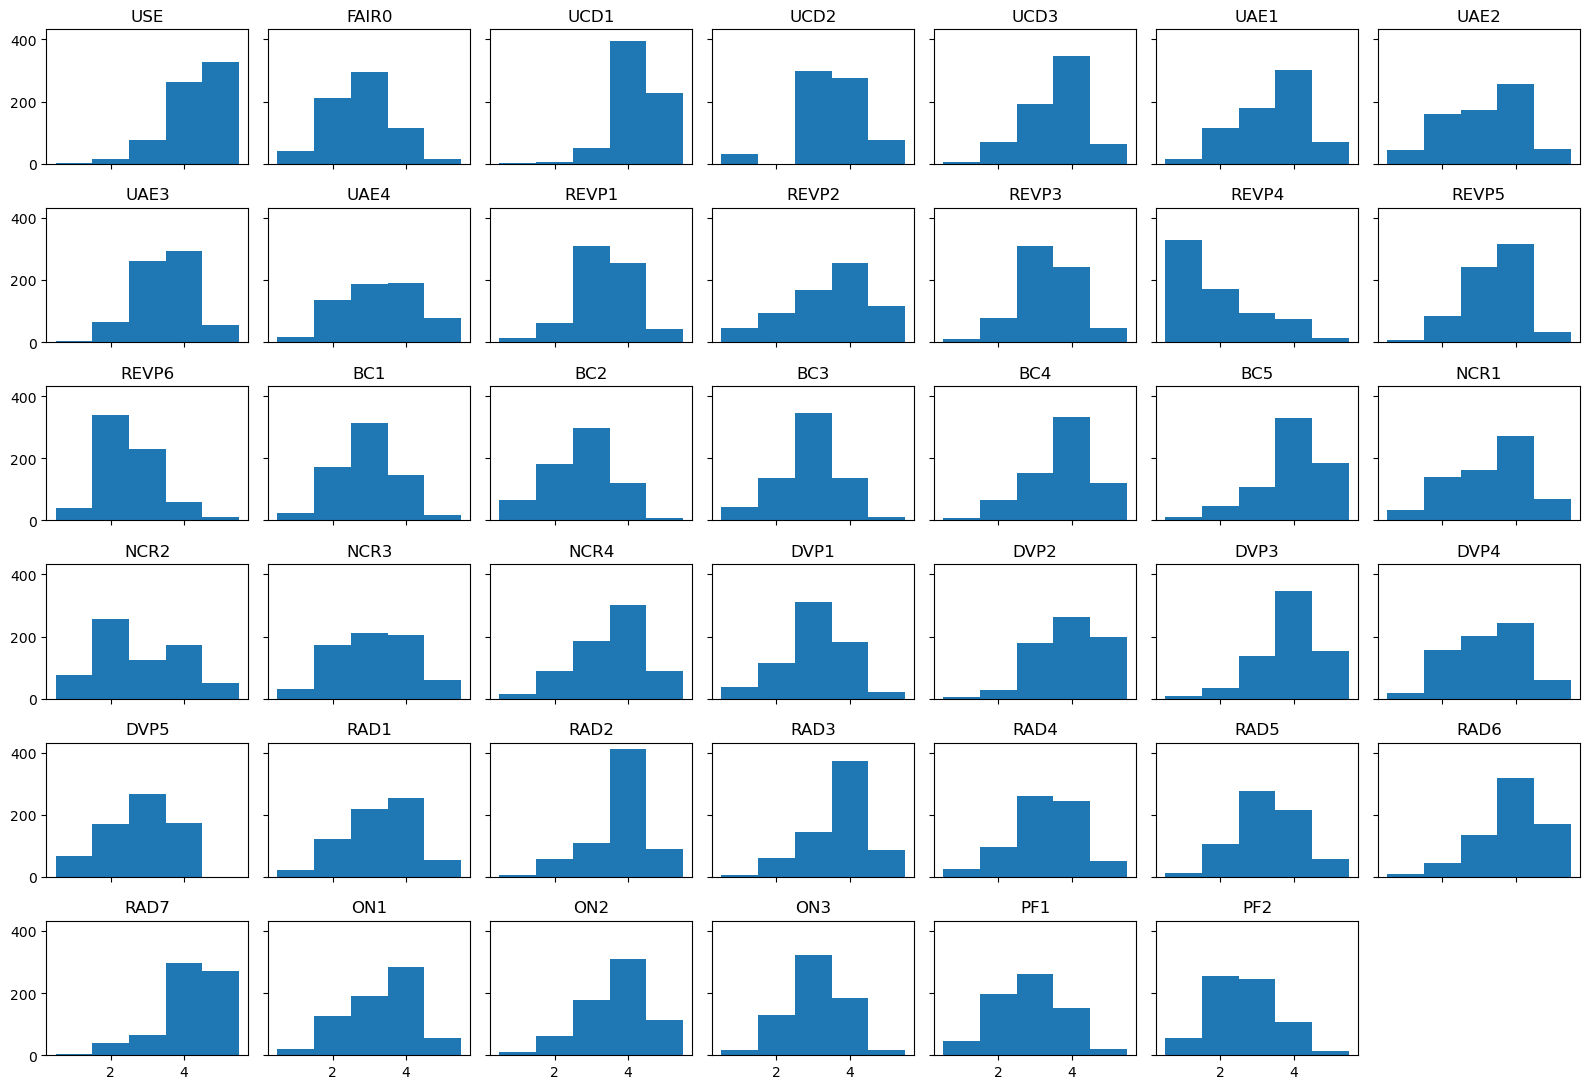

In [40]:
#Huyen: Look at distribution of answers
questions = survey_items[['USE', 'FAIR0',
       'UCD1', 'UCD2', 'UCD3', 'UAE1', 'UAE2', 'UAE3', 'UAE4', 'REVP1',
       'REVP2', 'REVP3', 'REVP4', 'REVP5', 'REVP6', 'BC1', 'BC2', 'BC3', 'BC4',
       'BC5', 'NCR1', 'NCR2', 'NCR3', 'NCR4', 'DVP1', 'DVP2', 'DVP3', 'DVP4',
       'DVP5', 'RAD1', 'RAD2', 'RAD3', 'RAD4', 'RAD5', 'RAD6', 'RAD7', 'ON1',
       'ON2', 'ON3', 'PF1', 'PF2']]

# One small histogram for each question
fig, axes = plt.subplots(6, 7, figsize=(16, 11), sharex=True, sharey=True)   # a grid of 6 rows x 7 columns. sharex/sharey: all charts use the same scale
axes = axes.flatten()                       # make a simple list of the 42 charts

bins = [0.5, 1.5, 2.5, 3.5, 4.5, 5.5]       # answers are 1 to 5, so one bar for each answer

i = 0                                       # i = the number of the chart we draw now
for name in questions.columns:              # go through the questions one by one
    answers = questions[name].dropna()      # remove missing answers
    axes[i].hist(answers, bins=bins)        # draw the histogram on chart number i
    axes[i].set_title(name)                 # the question code as the title
    i = i + 1                               # go to the next chart

axes[41].axis("off")                        # hide the last chart, because we have only 41 questions

plt.tight_layout()                          # avoid overlapping text
plt.show()

*learning source: histogram: https://www.geeksforgeeks.org/data-visualization/plotting-histogram-in-python-using-matplotlib/*

In [41]:
# Huyen: look at simple statistics of value ranks
value_rank = data[['rank_autonomy', 'rank_democracy', 'rank_equality', 'rank_equity']]
value_rank.describe()

,rank_autonomy,rank_democracy,rank_equality,rank_equity
count,616.000000,616.000000,616.000000,616.000000
mean,2.073052,2.357143,2.522727,3.047078
std,1.071214,1.061850,1.055902,1.055866
min,1.000000,1.000000,1.000000,1.000000
25%,1.000000,1.000000,2.000000,2.000000
50%,2.000000,2.000000,3.000000,3.000000
75%,3.000000,3.000000,3.000000,4.000000
max,4.000000,4.000000,4.000000,4.000000


In [42]:
for col in value_rank.columns:
    missing_pct = value_rank[col].isnull().mean() * 100
    print(f"{col}: {value_rank[col].isnull().sum()} missing ({missing_pct:.2f}%)")


rank_autonomy: 69 missing (10.07%)
rank_democracy: 69 missing (10.07%)
rank_equality: 69 missing (10.07%)
rank_equity: 69 missing (10.07%)


In [43]:
# Huyen: look at simple statistics of dummy columns
dummy_col = data[['country_group', 'parent_group',
       'parents_non_eu', 'age_group', 'education_level', 'heavy_user',
       'english_online', 'top_value', 'country_located_Germany',
       'country_located_Greece', 'country_located_Netherlands',
       'country_located_Other', 'country_located_Spain', 'gender_Female',
       'gender_Male', 'gender_Other', 'age_18-24', 'age_25-34', 'age_35+',
       'age_Under 18', 'top_Autonomy', 'top_Democratic', 'top_Equality',
       'top_Equity']]
dummy_col.describe()

,parents_non_eu,education_level,heavy_user,english_online,country_located_Germany,country_located_Greece,country_located_Netherlands,country_located_Other,country_located_Spain,gender_Female,gender_Male,gender_Other,age_18-24,age_25-34,age_35+,age_Under 18,top_Autonomy,top_Democratic,top_Equality,top_Equity
count,681.000000,680.000000,682.000000,683.000000,680.000000,680.000000,680.000000,680.000000,680.000000,680.000000,680.000000,680.000000,682.000000,682.000000,682.000000,682.000000,616.000000,616.000000,616.000000,616.000000
mean,0.287812,2.879412,0.478006,0.884334,0.222059,0.111765,0.436765,0.063235,0.166176,0.516176,0.473529,0.010294,0.555718,0.328446,0.093842,0.021994,0.405844,0.266234,0.209416,0.118506
std,0.453076,0.949468,0.499883,0.320059,0.415936,0.315309,0.496350,0.243565,0.372513,0.500106,0.499666,0.101011,0.497250,0.469993,0.291822,0.146772,0.491454,0.442347,0.407222,0.323470
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,3.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,4.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
max,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [44]:
#Huyen
# Share (%) of people in each group, calculated from the 0/1 dummy columns
# The mean of a 0/1 column = the share of 1s. Multiply by 100 to get a percentage.

groups = {
    "Country": ["country_located_Netherlands", "country_located_Germany", "country_located_Spain",
                "country_located_Greece", "country_located_Other"],
    "Gender": ["gender_Female", "gender_Male", "gender_Other"],
    "Age": ["age_18-24", "age_25-34", "age_35+", "age_Under 18"],
    "Most important value": ["top_Autonomy", "top_Democratic", "top_Equality", "top_Equity"],
    "Other flags": ["heavy_user", "english_online"],
}

for group_name in groups:                    # go through Country, Gender, Age, ...
    print(group_name)
    for column in groups[group_name]:        # go through the dummy columns of this group
        share = data[column].mean() * 100    # mean ignores missing values (NaN)
        print("   ", column, ":", round(share, 1), "%")
    print()


Country
    country_located_Netherlands : 43.7 %
    country_located_Germany : 22.2 %
    country_located_Spain : 16.6 %
    country_located_Greece : 11.2 %
    country_located_Other : 6.3 %

Gender
    gender_Female : 51.6 %
    gender_Male : 47.4 %
    gender_Other : 1.0 %

Age
    age_18-24 : 55.6 %
    age_25-34 : 32.8 %
    age_35+ : 9.4 %
    age_Under 18 : 2.2 %

Most important value
    top_Autonomy : 40.6 %
    top_Democratic : 26.6 %
    top_Equality : 20.9 %
    top_Equity : 11.9 %

Other flags
    heavy_user : 47.8 %
    english_online : 88.4 %



### Summary of encoded data, 685 respondents, 72 numeric columns
Huyen

**Missing data**
- Most columns have 670–682 valid answers (under 3% missing).
- UAE4 has 605 answers: the 80 missing are "I don't know".
- `rank_value` have 616 answers: 69 people skipped the values ranking.

**Survey items (1–5, higher = more agreement / more often)**
- Highest means: USE (4.31), UCD1 (4.23), RAD7 (4.17), BC5 (3.93), DVP2 (3.92), DVP3 (3.88), RAD6 (3.88). Most people use social media often/always, see biased political content and believe the algorithm shapes what they see.
- Lowest means: REVP4 (1.94), REVP6 (2.50), PF2 (2.66), BC2 (2.73), FAIR0 (2.78), DVP5 (2.81), NCR2 (2.81). The fairness items (FAIR0, PF1, PF2) are below the scale midpoint of 3, so feeds are seen as somewhat unfair.
- Spread: SD from 0.64 (UCD1, most agreed-on) to 1.16 (NCR2). All items use the full 1–5 range, except DVP5 (1–4).

**Other numeric columns**
- `n_languages` mean 2.74 (1–4); `education_level` mean 2.88 (1 = secondary or less, 4 = Master +).
- Value ranks (1 = most important): autonomy 2.07, democracy 2.36, equality 2.52, equity 3.05. Autonomy is ranked most important, equity least.

**Dummy columns: 0/1 columns (mean = share of respondents)**
- Country: Netherlands 43.7%, Germany 22.2%, Spain 16.6%, Greece 11.2%, Other 6.3%.
- Parents' origin: Native 49.8%, Both other-EU 21.4%, Both non-EU 20.3%, Mixed 8.5%; `parents_non_eu` = 28.8%.
- Gender: Female 51.6%, Male 47.4%, Other 1.0% (too small to compare).
- Age: 18-24 55.6%, 25-34 32.8%, 35+ 9.4%, Under 18 2.2%.
- Most important value: Autonomy 40.6%, Democratic 26.6%, Equality 20.9%, Equity 11.9%.
- `heavy_user`: use social media "always" 47.8%, `english_online`: use english in social media 88.4%


# V. Group relevant survey questions into target variables
 Author: Huyen



diversity_items  = ["UCD2", "REVP5", "ON1"]
    • UCD2: I see different opinions on the same topic, 
    • REVP5: I often see new ideas and topics on my feed, 
    • ON1 I feel like my feed keeps me well-informed (e.g., news, social issues, or different opinions)

echo_items       = ["REVP1", "REVP2", "REVP3"]
    • REVP1: When I see a post and open the comments, the top comments reflect what I am already thinking
    about, 
    • REVP2: I scroll through the comments to see if someone has mentioned what I am thinking about
    • REVP3: I notice a lot of agreement within comments

visibility_items = ["BC2", "BC3", "ON3"]
    • BC2: My content gets the same number of views as content from others
    • BC3: My content gets as many views as others from different backgrounds (e.g., race)
    • ON3: I feel like I have a fair chance to be seen/heard

control_items    = ["RAD1", "RAD2"]
    • RAD1: I feel I am in control of my feed
    • RAD2: I can influence the type of content I get on my feed

suspicion_items  = ["DVP2", "DVP3", "ON2", "DVP5", "BC4"]
    • DVP2: I have seen political content that felt biased
    • DVP3: I feel like the algorithm shapes what political topics I get to see
    • DVP5: I’ve seen creators mention that their political-related content was shadowbanned
    • ON2: I believe that certain views (political) are hidden
    • BC4: I think content from certain groups of people is prioritized over other groups

fairness_items   = ["PF1", "PF2", "FAIR0"]
    • PF1: I trust algorithms to recommend me content fairly
    • PF2: I think social media platforms treat users and content fairly
    • FAIR0: I think social media is fair

In [45]:
# Huyen: create lists of variables with relevant questions
diversity_items  = ["UCD2", "REVP5", "ON1"]
echo_items       = ["REVP1", "REVP2", "REVP3"]
visibility_items = ["BC2", "BC3", "ON3"]
control_items    = ["RAD1", "RAD2"]
suspicion_items  = ["DVP2", "DVP3", "ON2", "DVP5", "BC4"]
fairness_items   = ["PF1", "PF2", "FAIR0"]

all_items = diversity_items + echo_items + visibility_items + control_items + suspicion_items + fairness_items
print("Number of questions in the model:", len(all_items))

Number of questions in the model: 19


Huyen: SEM needs complete answers, so I drop missing answers from relevant questions

In [46]:
# Huyen: drop missing answers from relevant questions
SEM_data = data.dropna(subset=all_items).copy()
print("Total answers, including incomplete one:", len(data))
print("People with complete answers:", len(SEM_data))

Total answers, including incomplete one: 685
People with complete answers: 646


Huyen: Look at descriptive statistics of relevant variables

In [47]:
# Huyen
variables = {
    "Diversity":  diversity_items,
    "Echo":       echo_items,
    "Visibility": visibility_items,
    "Control":    control_items,
    "Suspicion":  suspicion_items,
    "Fairness":   fairness_items,
}

scores = pd.DataFrame() # create scores dataframe
for item in variables:  # loop each item (relevant answer's score of each question)
    scores[item] = SEM_data[variables[item]].mean(axis=1)

summary = pd.DataFrame()
summary["mean"] = scores.mean()
summary["sd"] = scores.std()
summary["min"] = scores.min()
summary["max"] = scores.max()
summary.round(2)


,mean,sd,min,max
Diversity,3.43,0.61,1.33,5.00
Echo,3.39,0.66,1.67,5.00
Visibility,2.91,0.62,1.00,5.00
Control,3.53,0.75,1.00,5.00
Suspicion,3.62,0.56,1.80,4.80
Fairness,2.76,0.72,1.00,4.67


what the summary show:

- Factor scores on a 1-5 scale

- **Suspicion is the highest mean (3.62)**. People generally do not fully trust how algorithms choose and organise the content they see in their feeds. It also has the lowest SD (0.56), People's answers are quite similar to each other. There is less variation in their responses, so most people feel this way.

- Suspicion score from 1.8 to 4.8, so nobody scores very low on it.

- Following by **Control: 3.53, Diversity: 3.43, and Echo: 3.39. they are all moderately above the midpoint of 3. This means that people generally have a slightly positive experience with their social media feeds, but not strongly.Users feel somewhat in control, see some variety, and notice that their feeds sometimes show content that matches their existing opinions or beliefs

- Control varies the most (SD 0.75). People differ a lot in how much control they feel.

- Visibility (2.91) is the only experience score below 3. On average, people feel their content is not seen as much as others' content.

- Fairness is the lowest (2.76). It is below the midpoint, so users see social media as slightly unfair. This fits the pattern: higher suspicion and lower visibility go with lower perceived fairness.




visualise average score per factor

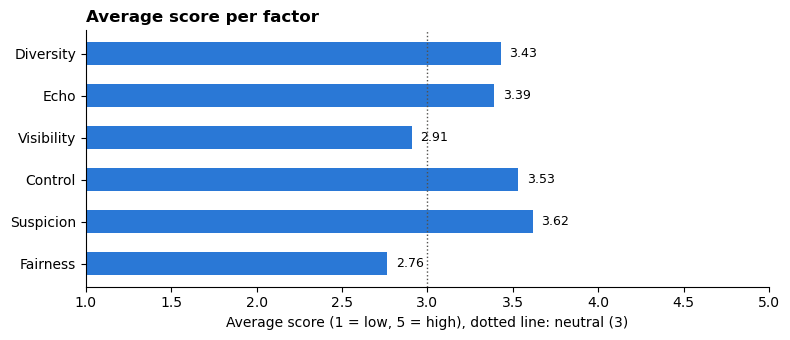

In [48]:
#Huyen:
# Create bar chart of the averages, with a dotted line at 3 as neutral, because score from 1 - 5
fig, ax = plt.subplots(figsize=(8, 3.5))
names = list(summary.index)

ax.barh(names, summary["mean"], color="#2a78d6", height=0.55)
ax.axvline(3, color="#52514e", linestyle=":", linewidth=1)

for i in range(len(names)): # create data labels
    ax.text(summary["mean"].iloc[i] + 0.05, i, round(summary["mean"].iloc[i], 2), va="center", fontsize=9)

ax.set_xlim(1, 5)
ax.invert_yaxis()
ax.set_xlabel("Average score (1 = low, 5 = high), dotted line: neutral (3)")
ax.set_title("Average score per factor", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

*learning source: bar chart: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar_label.html#matplotlib.axes.Axes.bar_label*

Insights from the average score per factor: 
- People are quite suspicious of the algorithm with 3.62, above neutral of 3.
- Fairness is rated low at 2.76, below neutral.
- People feel moderately in control: 3.53, but their visibility is below neutral (2.91).

Huyen: Look at correlations between the factor scores

I want to see how strongly two things move together (−1 to +1).

In [49]:
scores.corr().round(2)

,Diversity,Echo,Visibility,Control,Suspicion,Fairness
Diversity,1.00,0.19,0.20,0.21,-0.10,0.37
Echo,0.19,1.00,0.08,0.15,0.03,0.21
Visibility,0.20,0.08,1.00,0.16,-0.16,0.33
Control,0.21,0.15,0.16,1.00,-0.08,0.26
Suspicion,-0.10,0.03,-0.16,-0.08,1.00,-0.38
Fairness,0.37,0.21,0.33,0.26,-0.38,1.00


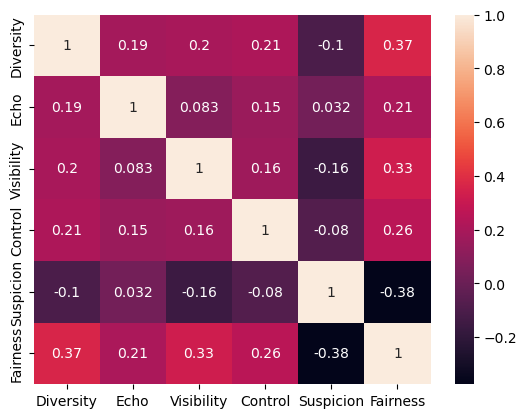

In [50]:
#plotting the heatmap for correlation
import seaborn as sns
ax = sns.heatmap(scores.corr(), annot=True)

*learning source: seaborn heatmap: https://seaborn.pydata.org/generated/seaborn.heatmap.html*

Insight from corr between factors:

**Fairness** has the strongest *negative* correlation with **Suspicion**, and *positive* correlations with **Diversity, Visibility and Control**. None of the correlations is above 0.85, so the factors are clearly different from each other.

# VI. Check the SEM assumptions
Author: Huyen

- Do data have enough answer?. Because SEM needs a large sample. check: if N ≥ 200
- Are answers roughly normal?. Because the estimation method (maximum likelihood) assumes it. Check: 	Skewness and kurtosis
- Are factors not too similar?.	Otherwise the model can't separate them. Check:	Correlations < 0.85

Why I check skew and kurtosis:

- SEM method assumes the answers are roughly normal, the bell-shaped pattern. If the answers are far from normal, the estimates and p-values can be wrong.

- Skew shows whether answers are pushed to one side. For example, most people answer 4–5 and only a few answer 1. Good/acceptable rule is that skew between −1 and +1.

- Kurtosis shows whether the shape is too peaked or too flat. Good/acceptable rule is that kurtosis between -2 and +2.


In [51]:
# Check 1: is the sample big enough? SEM is used on the people with complete answers, using SEM_data)
n = len(SEM_data)
print("Sample size:", n)
if n >= 200:
    print("OK")
else:
    print("too small")
print()

# Check 2: skewness and kurtosis of each question
skew_list = []
kurtosis_list = []
for item in all_items:                              # go through the 19 questions one by one
    skew_list.append(stats.skew(SEM_data[item]))            # skew: are answers pushed to one side?
    kurtosis_list.append(stats.kurtosis(SEM_data[item]))    # kurtosis: is the shape too peaked or too flat?

normality = pd.DataFrame()                          # put the numbers in a table
normality["skew"] = skew_list
normality["kurtosis"] = kurtosis_list
normality.index = all_items                         # the question codes as row names
normality = normality.round(2)

# abs() removes the minus sign, so -0.9 and +0.9 are both "0.9 away from normal"
print("Largest skew:", normality["skew"].abs().max())
print("Largest kurtosis:", normality["kurtosis"].abs().max())
normality.T                                         # Transpose rows and columns

Sample size: 646
OK

Largest skew: 0.89
Largest kurtosis: 1.4


,UCD2,REVP5,ON1,REVP1,REVP2,REVP3,BC2,BC3,ON3,RAD1,RAD2,DVP2,DVP3,ON2,DVP5,BC4,PF1,PF2,FAIR0
skew,-0.59,-0.50,-0.38,-0.29,-0.53,-0.17,-0.13,-0.28,-0.13,-0.30,-0.89,-0.47,-0.74,-0.48,-0.36,-0.59,0.02,0.25,0.09
kurtosis,1.40,-0.11,-0.48,0.39,-0.45,0.10,-0.38,0.10,-0.12,-0.46,0.92,-0.26,0.72,-0.10,-0.73,0.07,-0.47,-0.35,-0.21


*learning source: Skewness and Kurtosis: https://www.geeksforgeeks.org/data-science/how-to-calculate-skewness-and-kurtosis-in-python/*

What I see:

- Sample size = 646 is OK.
- The largest values are 0.89 for skew and 1.4 for kurtosis. Both are inside the limits, so each question on its own is close to normal


# VII. Measurement model: do my question measure what I think?

Author: Huyen
CFA - Confirmatory Factor Analysis: I check that each group of questions really measures one factor

Notes in semopy:
- `=~` means *"is measured by"*
- `~` means *"is predicted by"* (regression)
- `~~` means *"is correlated with"*



In [52]:
#Huyen
cfa_model = '''
Diversity  =~ UCD2 + REVP5 + ON1
Echo       =~ REVP1 + REVP2 + REVP3
Visibility =~ BC2 + BC3 + ON3
Control    =~ RAD1 + RAD2
Suspicion  =~ DVP2 + DVP3 + ON2 + DVP5 + BC4
Fairness   =~ PF1 + PF2 + FAIR0
'''

cfa = semopy.Model(cfa_model)
cfa.fit(SEM_data)
print("CFA fitted!")


CFA fitted!


*learning source: semopy: https://semopy.com/,
cfa: https://www.geeksforgeeks.org/data-science/confirmatory-factor-analysis/*

In [53]:
#Huyen: Check model fit: does the model match the data?
# Calculates statistics to check how well the CFA model fits the data.
fit = semopy.calc_stats(cfa).T["Value"] # Transposes rows and columns.
fit_table = pd.DataFrame({
    "value":  [fit["chi2"], fit["DoF"], round(fit["chi2"] / fit["DoF"], 2), round(fit["RMSEA"], 3), round(fit["CFI"], 3), round(fit["TLI"], 3)],
    "good if": ["", "", "below 3", "below 0.1", "above 0.95", "above 0.95"]},
    index=["chi2", "df", "Chi-square / df", "RMSEA", "CFI", "TLI"])
fit_table 

,value,good if
chi2,379.745379,
df,137.000000,
Chi-square / df,2.770000,below 3
RMSEA,0.052000,below 0.1
CFI,0.870000,above 0.95
TLI,0.838000,above 0.95


*learning source: fit indices: https://semopy.com/indices.html*

Conclusion: 
- **Fit:** RMSEA (~ 0.052) and chi-square/df (~ 2.77) are good. CFI (~ 0.87) and TLI (~ 0.84) are a bit below 0.95. The model is acceptable, but not perfect.

### Factor loadings: how strongly does each question belong to its factor?
A **standardised loading** above about 0.40 is usually fine; above 0.70 is very good.

In [54]:
#Huyen
# get all the results of the CFA model as a table, get the results of CFA model, such as factor loadings, relationships between variables, and error variances.
cfa_results = cfa.inspect(std_est=True)      # std_est=True: also give the standardised numbers (column "Est. Std")

# keep only the loadings
# In semopy, a loading has sign "~" in the column "op" (operator), and the factor name in the column "rval"
factor_names = ["Diversity", "Echo", "Visibility", "Control", "Suspicion", "Fairness"]
is_loading = cfa_results["op"] == "~"                      # True for the rows that are loadings
is_factor = cfa_results["rval"].isin(factor_names)         # True for the rows where rval is one of our 6 factors
loadings = cfa_results[is_loading & is_factor]             # keep rows where both are True

#keep only the 4 columns we need, with clearer names
loadings = loadings[["rval", "lval", "Est. Std", "p-value"]]
loadings.columns = ["factor", "question", "std. loading", "p-value"]

#show the table with 3 decimals
loadings.round(3)

,factor,question,std. loading,p-value
0,Diversity,UCD2,0.482,-
1,Diversity,REVP5,0.414,0.0
2,Diversity,ON1,0.567,0.0
3,Echo,REVP1,0.600,-
4,Echo,REVP2,0.657,0.0
5,Echo,REVP3,0.344,0.0
6,Visibility,BC2,0.668,-
7,Visibility,BC3,0.667,0.0
8,Visibility,ON3,0.329,0.0
9,Control,RAD1,1.000,-


*learning source: https://semopy.com/docs/model.html, https://pypi.org/project/semopy/, https://labeeb.ae/cfa-sem-model-fit-thresholds/, https://www.digitalocean.com/community/tutorials/structural-equation-modeling-complete-guide
*

Explanation:
- **Loadings:** every question loads on its factor, mostly between 0.4 and 0.8. A few are weak: REVP3, ON3, BC4 (≈ 0.34–0.39).

- RAD1 loading of 1.0: RAD1 has a standardised loading of exactly 1.000, and RAD2 has 0.428. Control has only two questions, so the model cannot separate the factor from RAD1

In [55]:
#Huyen
# check how strongly RAD1 and RAD2 correlate with each other?
SEM_data[["RAD1", "RAD2"]].corr()

,RAD1,RAD2
RAD1,1.000000,0.428677
RAD2,0.428677,1.000000


- With a correlation of above 0.4, RAD1 and RAD2 is moderate correlate with each other.

- With RAD1 loading of 1.0, this is impossible or unusual result, usually a negative error variance.(no question is perfect).

- With only 2 questions, the model is unstable.

- So, my solution is using Average of RAD1 and RAD2 (RAD1+RAD2)/2, so each person gets one Control number.

### Perceived control: one average score
After you take Average, Control is no longer a hidden factor. It is one ordinary measured number


In [56]:
#Huyen
SEM_data["Control"] = (SEM_data["RAD1"] + SEM_data["RAD2"]) / 2
SEM_data["Control"].describe().round(2)

count    646.00
mean       3.53
std        0.75
min        1.00
25%        3.00
50%        3.50
75%        4.00
max        5.00
Name: Control, dtype: float64

### Check alpha for reliability
Huyen:

I want to look at alpha to check whether the questions of one factor give consistent answer.

Formula: α = k/(k−1) × (1 − sum of item variances / variance of the total score)

Cronbach's Alpha Thresholds:

- **≥ 0.90: Excellent / Very Strong**. The items are highly consistent. 
- **0.80 - 0.89: Good / Strong**. It indicates a reliable instrument without excessive redundancy.
- **0.70 - 0.79: Acceptable / Moderate**. This is the standard minimum threshold for most established scales.

- **0.60 - 0.69: Questionable / Weak**. it suggests the items do not hang together well.
- **< 0.60: Poor / Unacceptable**. The scale is unreliable, and the items should not be aggregated into a single latent construct.




In [57]:
# Cronbach's alpha: do the questions of one factor give consistent answers?
# Formula: alpha = k / (k - 1) x (1 - sum of item variances / variance of the total score)

def cronbach_alpha(table):
    k = table.shape[1]                       # k = number of questions (number of columns)
    item_variances = table.var().sum()       # variance of each question (column), then add them up
    total_score = table.sum(axis=1)          # axis=1: add the questions of each person (row) = total score
    total_variance = total_score.var()       # variance of the total scores
    alpha = k / (k - 1) * (1 - item_variances / total_variance)
    return alpha

for factor in variables:                     # go through Diversity, Echo, ...
    questions_of_factor = variables[factor]  # the list of questions of this factor
    table = SEM_data[questions_of_factor]    # keep only these columns
    alpha_value = cronbach_alpha(table)
    print(factor, ": alpha =", round(alpha_value, 2))

Diversity : alpha = 0.48
Echo : alpha = 0.52
Visibility : alpha = 0.54
Control : alpha = 0.59
Suspicion : alpha = 0.62
Fairness : alpha = 0.71


Fairness is OK and acceptable with alpha ~ 0.71. The other factors are weak around 0.48-0.62. This is limitation of the questionnaire.

*learning source: https://paperguide.ai/research-glossary/cronbachs-alpha/*

# VIII. Structural model:
# Huyen: answering Sub-Question 1

1. Antecedents → mediators: How do content diversity, echo and visibility shape users' sense of control and suspicion of algorithmic curation?

#### Hypothesis:

**Hypothesis 1**: What makes users feel more in control?

`My assumption`: The more users experience diversity, familiar content and visibility, the more control they may feel they have over their social media experience.

H1a: Diversity -> Control: When users see different types of content and opinions, they feel more in control of their feed rather than feeling controlled by the algorithm.

H1b: Echo -> Control: When users see content that matches their interests and opinions, they may feel that the feed reflects their own preferences and choices.

H1c: Visibility -> Control: When users feel that their content and opinions are visible to others, they may feel they have more influence and control on the platform.

**Hypothesis 2**: What makes users trust or question the algorithm?

`My assumption`: Seeing diverse content and feeling visible may reduce users' suspicion, while repeatedly seeing similar content may increase it.

H2a: Diversity -> Suspicion: When users see different types of content and opinions, they may be less suspicious of how the algorithm selects content.

H2b: Echo -> Suspicion: When users repeatedly see similar content and opinions, they may start questioning whether the algorithm is filtering what they see.

H2c: Visibility -> Suspicion: When users feel their content and opinions are visible to others, they may be less suspicious that the algorithm is hiding or suppressing their content.


In [58]:
#Huyen
sem_model = '''
# measurement part
Diversity  =~ UCD2 + REVP5 + ON1
Echo       =~ REVP1 + REVP2 + REVP3
Visibility =~ BC2 + BC3 + ON3
Suspicion  =~ DVP2 + DVP3 + ON2 + DVP5 + BC4
Fairness   =~ PF1 + PF2 + FAIR0

# structural part (the arrows)
Control   ~ Diversity + Echo + Visibility
Suspicion ~ Diversity + Echo + Visibility
Fairness  ~ Control + Suspicion + Diversity + Echo + Visibility

# mediators may be correlated
Control ~~ Suspicion
'''

model = semopy.Model(sem_model)
model.fit(SEM_data)
fit = semopy.calc_stats(model).T["Value"]
print("RMSEA:", round(fit["RMSEA"], 3), " CFI:", round(fit["CFI"], 3), " Chi2/df:", round(fit["chi2"] / fit["DoF"], 2))

RMSEA: 0.054  CFI: 0.864  Chi2/df: 2.9


*learning source: semopy: https://semopy.com/, https://www.digitalocean.com/community/tutorials/structural-equation-modeling-complete-guide*

The fit of the full model is close to the CFA: RMSEA = 0.054 is good, and CFI/TLI ~ 0.87/0.84 are a bit low. The model is acceptable for an exploratory study.

Check if p-value if it is significant?
- **beta** = unstandardised effect (in the original 1–5 units)
- **beta standardised** = standardised effect (−1 to 1), so I can compare which arrow is strongest
- **p-value < 0.05** is significant

In [59]:
#Huyen
# get all the results of the SEM model as a table
results = model.inspect(std_est=True)         # std_est=True: also give the standardised numbers (column "Est. Std")

# keep only the paths (arrows) between factors, not the loadings
# In semopy, "lval" is the variable the arrow points TO, "rval" is where it comes FROM, and "~" means "is explained by"
outcomes = ["Control", "Suspicion", "Fairness"]
is_path = results["op"] == "~"                # True for the rows that are arrows
is_outcome = results["lval"].isin(outcomes)   # True for the rows where the arrow points to one of the 3 outcomes
paths = results[is_path & is_outcome]         # keep rows where both are True

# keep 5 columns, with clearer names
paths = paths[["rval", "lval", "Estimate", "Est. Std", "p-value"]].copy()   # copy(): make our own table, so we can change it safely
paths.columns = ["from", "to", "beta", "beta standardised", "p-value"]
paths["p-value"] = paths["p-value"].astype(float)    # make sure the p-values are numbers, not text

# is the path significant? (p-value < 0.05 => yes, it's significant)
sig = []
for p in paths["p-value"]:
    if p < 0.05:
        sig.append("yes")
    else:
        sig.append("no")
paths["significant?"] = sig

paths.round(3)

,from,to,beta,beta standardised,p-value,significant?
0,Diversity,Control,0.447,0.248,0.001,yes
1,Echo,Control,0.182,0.118,0.044,yes
2,Visibility,Control,0.060,0.048,0.365,no
3,Diversity,Suspicion,-0.245,-0.211,0.018,yes
4,Echo,Suspicion,0.129,0.130,0.083,no
5,Visibility,Suspicion,-0.131,-0.164,0.018,yes
6,Control,Fairness,0.078,0.096,0.030,yes
7,Suspicion,Fairness,-0.589,-0.467,0.000,yes
8,Diversity,Fairness,0.499,0.340,0.000,yes
9,Echo,Fairness,0.173,0.138,0.026,yes


*learning source: https://semopy.com/syntax.html, https://cr-c.medium.com/variance-covariance-matrices-for-structural-equation-modeling-sem-in-python-d92f5a1f9a35 *

In [60]:
#Huyen
# How much of each outcome does the model explain? (R-squared)
# In the results table, the row where "lval" and "rval" are the same variable and op is "~~"
# shows the part of that variable the model can NOT explain (the error). So: R-squared = 1 - error.

r_squared = {}                                   # empty dictionary to keep the answers

for outcome in ["Control", "Suspicion", "Fairness"]:
    is_error_row = results["op"] == "~~"                 # "~~" = variance (the unexplained part)
    is_left = results["lval"] == outcome                 # the row is about this outcome
    is_right = results["rval"] == outcome                # on both sides = the variable with itself
    row = results[is_error_row & is_left & is_right]     # keep the one row where all three are True

    error = row["Est. Std"].iloc[0]              # iloc[0] = take the first (and only) value of the column
    r_squared[outcome] = round(1 - error, 2)     # R-squared = 1 - unexplained part, rounded to 2 decimals

print("R-squared:", r_squared)

R-squared: {'Control': 0.11, 'Suspicion': 0.08, 'Fairness': 0.6}


*learning source: https://pypi.org/project/semopy/, https://www.youtube.com/watch?v=ssRzHP1gOy8&t=106, https://semopy.com/syntax.html, https://cr-c.medium.com/variance-covariance-matrices-for-structural-equation-modeling-sem-in-python-d92f5a1f9a35, https://pandas.pydata.org/docs/user_guide/indexing.html*

In [61]:
# Colours I will use in my charts
BLUE = "#2a78d6"
RED = "#e34948"
GREY = "#a3a29c"
ORANGE = "#eb6834"



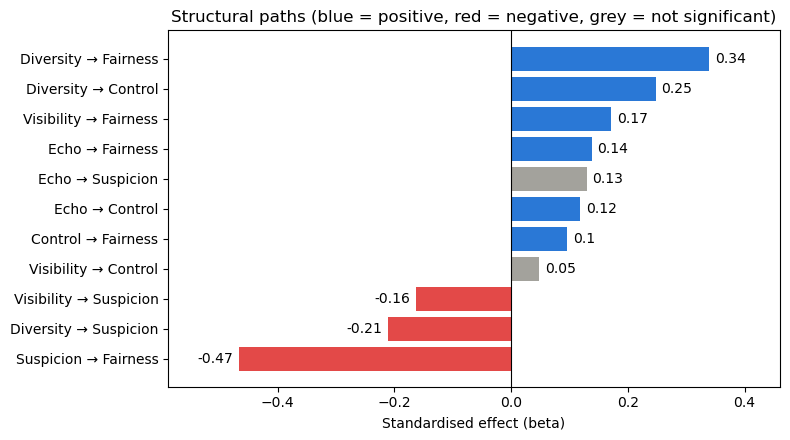

In [62]:
#Huyen
# Chart: all the paths, ordered by strength
chart = paths.copy()
chart["label"] = chart["from"] + " → " + chart["to"]      # e.g. "Diversity → Control"
chart = chart.sort_values("beta standardised")            # smallest effect at the bottom, biggest at the top

# Colour of each bar: grey = not significant, blue = significant and positive, red = significant and negative
colours = []
for i in range(len(chart)):                               # go through the paths one by one
    beta = chart["beta standardised"].iloc[i]             # the effect of path number i
    significant = chart["significant?"].iloc[i]           # "yes" or "no"
    if significant == "no":
        colours.append(GREY)
    elif beta > 0:
        colours.append(BLUE)
    else:
        colours.append(RED)

plt.figure(figsize=(8, 4.5))
plt.barh(chart["label"], chart["beta standardised"], color=colours)   # barh = horizontal bars

# Write the value at the end of each bar
for i in range(len(chart)):
    beta = chart["beta standardised"].iloc[i]
    if beta >= 0:
        plt.text(beta + 0.01, i, round(beta, 2), ha="left", va="center")     # positive: text on the right of the bar
    else:
        plt.text(beta - 0.01, i, round(beta, 2), ha="right", va="center")    # negative: text on the left of the bar
# plt.text(x, y, text): x = bar length, y = bar position; va="center" puts the text in the middle of the bar

plt.axvline(0, color="black", linewidth=0.8)              # a vertical line at 0
plt.margins(x=0.15)                                       # add space left and right, so the text is not cut
plt.xlabel("Standardised effect (beta)")
plt.title("Structural paths (blue = positive, red = negative, grey = not significant)")
plt.tight_layout()
plt.show()


*learning source: bar chart: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar_label.html#matplotlib.axes.Axes.bar_label*

### Huyen: answer to SQ1: feed experiences (diversity, echo, visibillity) → control and suspicion

- **Content diversity is the most important feed experience.** A diverse feed is associated with **more control** (β = 0.25, p: 0.001) and **reduce suspicion** (β = −0.21, p = 0.018).

- **Visibility reduce suspicion** (β = −0.16, p = 0.018), Users who feel they are seen fairly report lower suspicion. But doesn't significantly increase control (β = 0.05, p = 0.365).

- **Echo** has *NOT* significant link with suspicion as p > 0.05 (β = 0.13, p = 0.083), and has small link with control (β = 0.12, p = 0.044).

- The R² (variance) values are small (Control: 0.11, Suspicion: 0.08, Fairness: 0.6): the feed experiences explain only **11% of of the variance in control** and **8% of suspicion**. With R² of Fairness = 0.6, the model explains **about 60% of fairness**

| **Hypothesis** |	**Result** |
| -- | -- |
| H1a (Diversity → Control)	| supported (β = .248, p = .001) |
| H1b (Echo → Control) |	weakly supported (β = .118, p = .044) |
| H1c (Visibility → Control) |	not supported (β = .0048, p = .365) | 
| H2a (Diversity → Suspicion) |	supported (β = −.211, p = .018) |
| H2b (Echo → Suspicion) |	not supported ( β = .130, p = .083) |
| H2c (Visibility → Suspicion) |	supported (β = −.164, p = .018) |

### Huyen: Write formula for sub-question 1
$$\text{Control} = \beta_1\,\text{Diversity} + \beta_2\,\text{Echo} + \beta_3\,\text{Visibility} + \varepsilon_1$$

$$\text{Suspicion} = \beta_4\,\text{Diversity} + \beta_5\,\text{Echo} + \beta_6\,\text{Visibility} + \varepsilon_2$$

### Fill in the formula with my SEM results

In [63]:
# Write the regression formula of one outcome, for example: Control = 0.682*Diversity + 0.221*Echo + ... + error
# column tells which numbers to use: beta (original units 1 - 5) or beta standardised -1 to 1

def write_formula(outcome, column):
    rows = paths[paths["to"] == outcome]          # keep only the paths that point to this outcome
    text = outcome + " ="                         # the formula starts with e.g. "Control ="

    for i in range(len(rows)):                    # go through the paths one by one
        value = rows[column].iloc[i]              # the beta of path number i
        name = rows["from"].iloc[i]               # the name of the variable the arrow comes from
        number = f"{abs(value):.3f}"              # abs() removes the minus sign. :.3f = 3 decimals
        term = number + "*" + name                # e.g. "0.682*Diversity"

        if value >= 0:
            sign = "+"
        else:
            sign = "−"                            # a minus sign, because the beta is negative

        if i == 0:                                # the first term: no space after the sign, and no "+" in front
            if sign == "+":
                text = text + " " + term
            else:
                text = text + " −" + term
        else:                                     # the other terms: " + term" or " − term"
            text = text + " " + sign + " " + term

    return text + " + error"                      # every regression has an error term

print("UNSTANDARDISED (beta, original 1–5 units):\n")
for name in outcomes:
    print(write_formula(name, "beta"))

print("\nSTANDARDISED (beta standardised, compare the size of effects):\n")
for name in outcomes:
    print(write_formula(name, "beta standardised"))

UNSTANDARDISED (beta, original 1–5 units):

Control = 0.447*Diversity + 0.182*Echo + 0.060*Visibility + error
Suspicion = −0.245*Diversity + 0.129*Echo − 0.131*Visibility + error
Fairness = 0.078*Control − 0.589*Suspicion + 0.499*Diversity + 0.173*Echo + 0.173*Visibility + error

STANDARDISED (beta standardised, compare the size of effects):

Control = 0.248*Diversity + 0.118*Echo + 0.048*Visibility + error
Suspicion = −0.211*Diversity + 0.130*Echo − 0.164*Visibility + error
Fairness = 0.096*Control − 0.467*Suspicion + 0.340*Diversity + 0.138*Echo + 0.171*Visibility + error


*learning source: https://www.digitalocean.com/community/tutorials/structural-equation-modeling-complete-guide*

#### Visualizing SEM Models

In [69]:
import graphviz
print(graphviz.__version__)


0.21


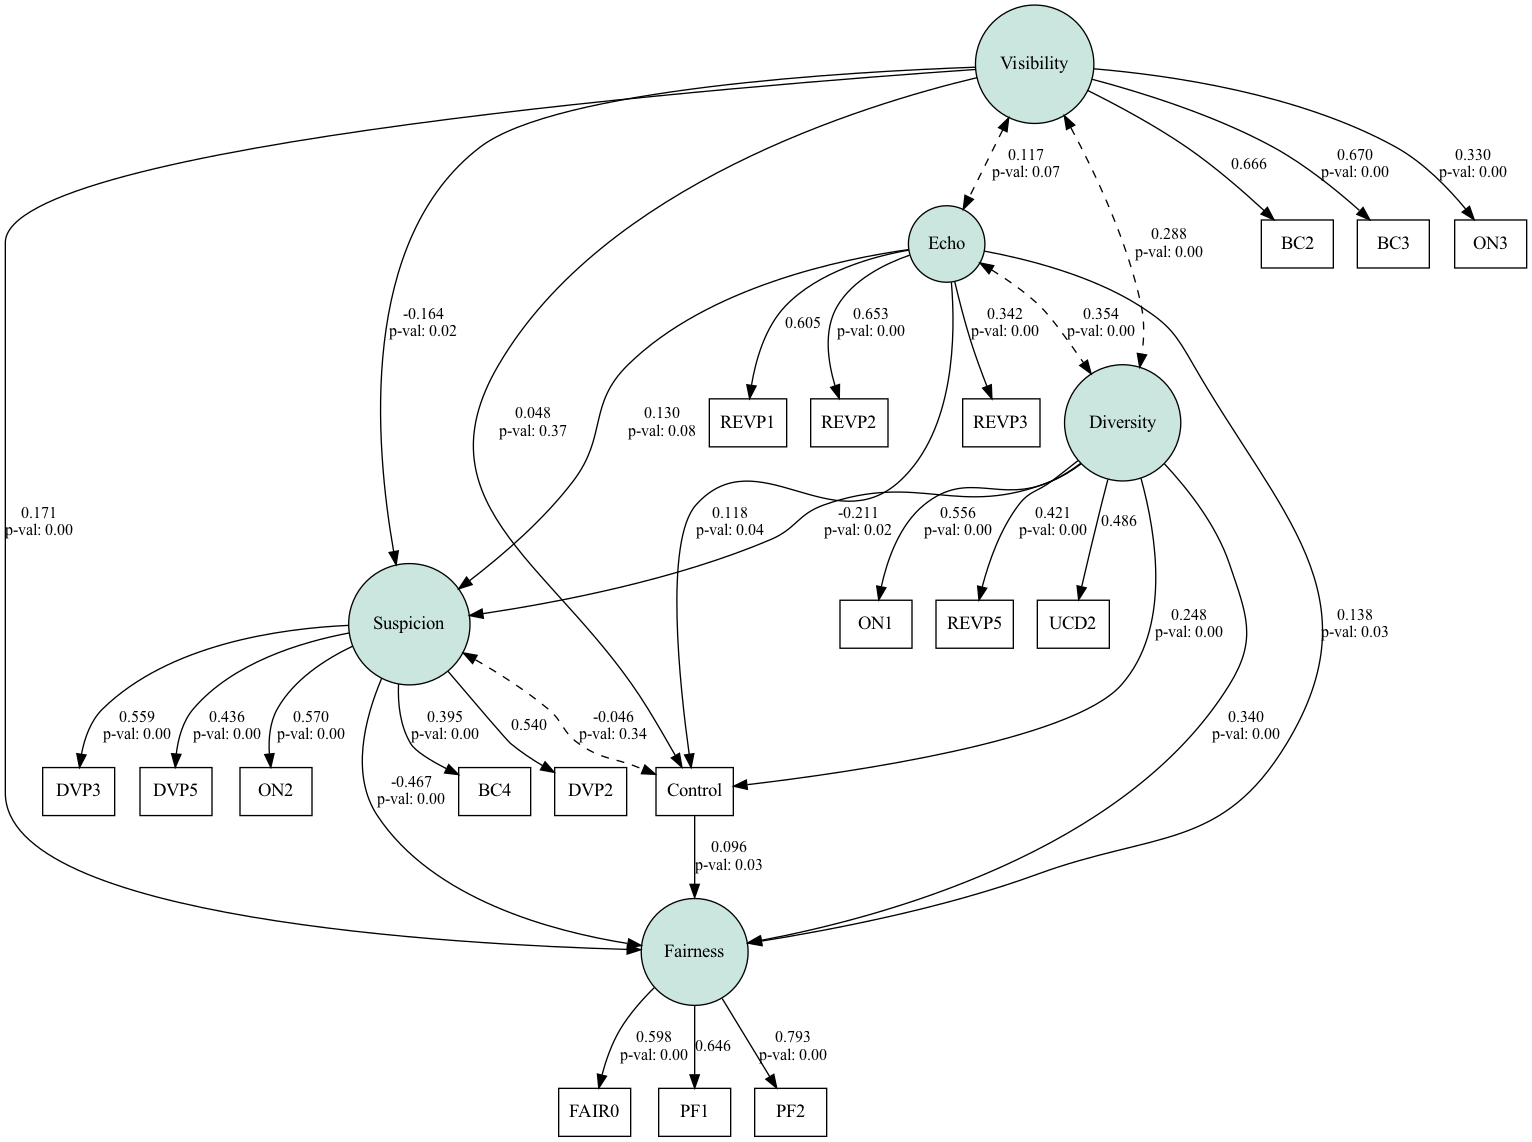

In [70]:
from semopy import semplot                    # semplot draws the SEM diagram
from IPython.display import Image             # Image shows a picture file inside the notebook

# 1. Draw the diagram and save it as a PNG file
semplot(model, "sem_diagram.png",
        plot_covs=True,        # also draw the curved arrow Control ~~ Suspicion
        std_ests=True)         # write standardised numbers (loadings and betas) on the arrows

# 2. Show the saved picture in the notebook
Image("sem_diagram.png")


*learning source: https://www.digitalocean.com/community/tutorials/structural-equation-modeling-complete-guide*

# IX. Cluster analysis for Sub-Question 1
Author: Huyen

SEM shows the effect of each experience separately. Clustering asks a different question: **which combinations of experiences do real users have?**

I group users by their three feed experiences only (diversity, echo, visibility). Then I check whether the groups differ in control and suspicion. I deliberately **don't** use control or suspicion to make the groups. Otherwise the groups would differ on those by construction, and the test would be circular.

**Method:** K-means clustering. First, I standardise the scores (mean 0, standard deviation 1) so each experience counts equally.

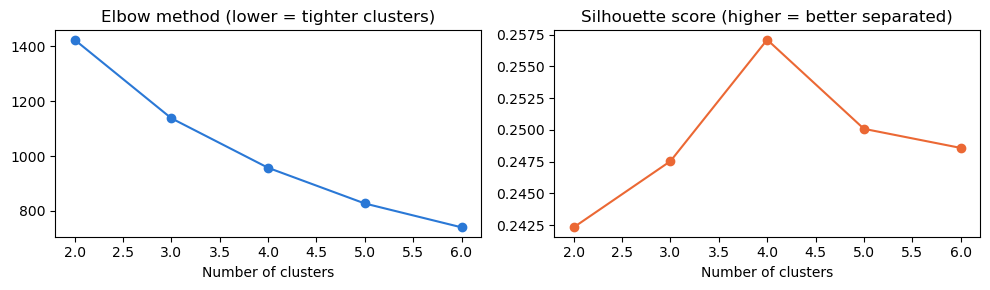

k = 2 : silhouette = 0.242
k = 3 : silhouette = 0.248
k = 4 : silhouette = 0.257
k = 5 : silhouette = 0.25
k = 6 : silhouette = 0.249


In [64]:
# Diversity, Echo and Visibility are factor scores, stored in `scores` (not in `data`)
experience_scores = scores[["Diversity", "Echo", "Visibility"]]

# Standardise: change each column to mean 0 and standard deviation 1, so each experience counts equally
scaled = StandardScaler().fit_transform(experience_scores)

# How many clusters? I try 2 to 6 and compare
cluster_numbers = [2, 3, 4, 5, 6]
inertia = []                                  # lists to keep the results of each k
silhouette = []

for k in cluster_numbers:
    kmeans = KMeans(n_clusters=k, n_init=50, random_state=42)   # n_init=50: try 50 starts, keep the best. random_state=42: same result every time
    labels = kmeans.fit_predict(scaled)       # the cluster number of each person
    inertia.append(kmeans.inertia_)           # inertia = how far people are from the centre of their cluster (lower = tighter)
    silhouette.append(silhouette_score(scaled, labels))   # silhouette = how well separated the clusters are (higher = better)

# Two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(cluster_numbers, inertia, marker="o", color=BLUE)   # marker="o": a dot at each k
axes[0].set_title("Elbow method (lower = tighter clusters)")
axes[0].set_xlabel("Number of clusters")

axes[1].plot(cluster_numbers, silhouette, marker="o", color=ORANGE)
axes[1].set_title("Silhouette score (higher = better separated)")
axes[1].set_xlabel("Number of clusters")

plt.tight_layout()
plt.show()

# Print the silhouette score of each k
# Silhouette: +1 = perfect clusters, 0 = people on the border between clusters, -1 = people in the wrong cluster
for j in range(len(cluster_numbers)):
    print("k =", cluster_numbers[j], ": silhouette =", round(silhouette[j], 3))

*learning source: https://scikit-learn.org/stable/api/sklearn.cluster.html*

In [65]:
# Stability check: if I resample the data, do I get the same clusters?
# Idea: make the clusters once on all the people (base), then make them again on
# 50 random re-draws of the people. If the new clusters look like the base ones, the result is stable.
# We compare two sets of clusters with the adjusted Rand index: 1 = identical clusters, 0 = random.

def stability(k, repeats=50):                   # k = number of clusters, repeats = how many re-draws
    base = KMeans(n_clusters=k, n_init=50, random_state=42).fit(scaled)   # clusters on all people
    rng = np.random.default_rng(0)              # random number generator (seed 0: same result every time)
    results = []                                # empty list to keep the 50 comparison scores

    for i in range(repeats):                    # repeat 50 times
        rows = rng.choice(len(scaled), len(scaled))   # pick random rows, same number as people. A person can be picked twice or not at all
        sample = scaled[rows]                   # the new data made from those rows
        refit = KMeans(n_clusters=k, n_init=10, random_state=i).fit(sample)   # make the clusters again on the new data
        new_labels = refit.predict(scaled)      # put ALL the original people into these new clusters
        score = adjusted_rand_score(base.labels_, new_labels)   # how similar are the base clusters and the new clusters?
        results.append(score)                   # save the score

    return np.mean(results)                     # the average of the 50 scores = the stability

for k in [3, 4]:
    print("k =", k, ": stability =", round(stability(k), 2))

k = 3 : stability = 0.69
k = 4 : stability = 0.62


**Choosing k = 3.** Four clusters has a slightly higher silhouette (0.257), but three clusters are **more stable** when I resample the data, and easier to describe. A silhouette of about 0.257 means the clusters overlap: they are tendencies, not completely separate types of users.

In [66]:
# K-means puts every person in one of 3 clusters
kmeans = KMeans(n_clusters=3, n_init=50, random_state=42)   # n_init=50: try 50 starts, keep the best
scores["cluster"] = kmeans.fit_predict(scaled)              # fit_predict gives the cluster number of each person

# average score of each cluster = its profile
columns = ["Diversity", "Echo", "Visibility", "Control", "Suspicion", "Fairness"]
profile = scores.groupby("cluster")[columns].mean()   # groupby: split people by cluster, then take the mean of each column
profile = profile.round(2)                            # round to 2 decimals
profile["n"] = scores["cluster"].value_counts()       # n = number of people in each cluster

# give each cluster a name, based on its averages
names = {}                                            # empty dictionary: cluster number -> name
rich = profile["Diversity"].idxmax()                  # idxmax: the cluster with the highest Diversity
narrow = profile["Visibility"].idxmin()               # idxmin: the cluster with the lowest Visibility
names[rich] = "Rich feeds"
names[narrow] = "Narrow & invisible"
for number in profile.index:                          # the cluster left over gets the last name
    if number not in names:
        names[number] = "Low-echo feeds"

# add the names to the data and to the profile table
scores["profile"] = scores["cluster"].map(names)      # map: replace each cluster number by its name
profile = profile.rename(index=names)                 # same replacement for the row labels of the table
profile

,Diversity,Echo,Visibility,Control,Suspicion,Fairness,n
cluster,,,,,,,
Narrow & invisible,2.93,3.44,2.29,3.33,3.76,2.44,176
Rich feeds,3.82,3.85,3.16,3.71,3.58,3.02,266
Low-echo feeds,3.35,2.75,3.12,3.47,3.54,2.72,204


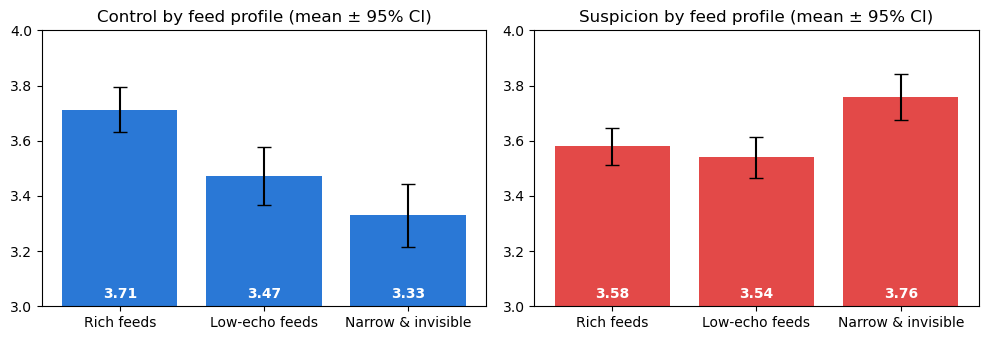

In [67]:
order = ["Rich feeds", "Low-echo feeds", "Narrow & invisible"]   # the order of the bars
variables_to_plot = ["Control", "Suspicion"]                     # one chart for each
colours = [BLUE, RED]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))   # 1 row, 2 charts side by side

for i in range(2):                                  # i = 0 is the first chart, i = 1 is the second
    variable = variables_to_plot[i]
    ax = axes[i]                                    # ax = the chart we draw on now

    # average score of each profile (reorder the rows with [order])
    means = scores.groupby("profile")[variable].mean()[order]

    # 95% confidence interval = 1.96 x standard error (sem). It is the error bar on top of each bar
    errors = scores.groupby("profile")[variable].sem()[order] * 1.96

    ax.bar(order, means, yerr=errors, color=colours[i], capsize=5)   # capsize = width of the error bar's end
    ax.set_ylim(3, 4)                               # y-axis from 3 to 4 so the differences are easier to see
    ax.set_title(variable + " by feed profile (mean ± 95% CI)") # CI: confidence interval

    # write the average inside each bar
    for j in range(3):                              # j = 0, 1, 2 is the position of the bar
        ax.text(j, 3.03, round(means.iloc[j], 2), ha="center", color="white", fontweight="bold")   # ha="center": text in the middle of the bar

plt.tight_layout()   # avoid overlapping text
plt.show()

In [68]:
# Do the profiles differ? I test Control and Suspicion one by one with ANOVA
for variable in ["Control", "Suspicion"]:

    # put the scores of each profile in its own list
    groups = []
    for p in order:
        one_group = scores[scores["profile"] == p][variable]
        groups.append(one_group)

    # ANOVA - do the group averages differ? (p < 0.05 = yes)
    anova = stats.f_oneway(*groups)

    print(variable)
    print("ANOVA F =", round(anova.statistic, 1), ", p-value =", round(anova.pvalue, 4))
    print()

Control
ANOVA F = 15.5 , p-value = 0.0

Suspicion
ANOVA F = 8.3 , p-value = 0.0003



*learning source: https://sustainabilitymethods.org/index.php/ANOVA_in_Python, https://experimentaldesignhub.com/blog/doe_09c/*

Conclusion:

the p-value is below 0.05, so at least one feed profile has a different average from the others in control and suspicion.

### Huyen: What the chart and ANOVA show (Control and Suspicion by feed profile)

The three feed profiles are groups of people with a similar feed. The bars show the **average score (1–5)** of each group. The black lines are the 95% confidence interval: the range where the true average probably is.

**Control (the feeling "I am in control of my feed")**
- **Rich feeds** feel the most control (average 3.71).
- **Low-echo feeds** are in the middle (3.47).
- **Narrow & invisible** feel the least control (3.33).
- ANOVA: F = 15.5, p < 0.001. The three groups do not have the same average control.

**Suspicion (the feeling "the algorithm is shaping or hiding what I see")**
- **Narrow & invisible** are the most suspicious (3.76).
- **Rich feeds** (3.58) and **Low-echo feeds** (3.54) are less suspicious, and almost the same as each other (their lines overlap).
- ANOVA: F = 8.3, p < 0.001. The three groups do not have the same average suspicion.

**Clusters agree with the SEM**. K-means found three feed profiles (stability ARI = 0.69). The profiles differ in control (F = 15.5, p < .001, η² = .046, small) and in suspicion (F = 8.3, p < .001). The rich-diversity profile reports the most control. The suspicion differences are small.

**What these mean:**
- People with a **rich and visible feed** feel more control and are less suspicious.
- People whose content is **not seen by others** (low visibility, low diversity) feel the least control and the most suspicion.
- The two charts are mirror images: where control is high, suspicion tends to be lower.

**Note:**
- ANOVA only tells us that *at least one* group is different. It does not tell exactly which pairs differ. 
- This is a link, not proof of a cause. I cannot say that the feed *causes* the feeling of control.


# Limitations:

- Weak measurement. Four of the six scales have Cronbach's alpha below 0.62 (Diversity is 0.48). Three items load below 0.40 (REVP3, ON3, BC4). Low reliability makes true effects look smaller.

- Model fit: CFI is about 0.86 and TLI about 0.84, below the usual 0.90 cut-off. The model does not match the survey data as well as expected. So I should be careful when interpreting the results and relationships between variables.

- Weak clusters. The silhouette score is about 0.25, so the profiles overlap and are tendencies, not distinct types. The rich-diversity profile scores highest on every item. That may partly reflect a general "agree with everything" answering style.

# The analysis for sub-question 2,3,4 are continued by Yasmina, Floris and Daniil